<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelStealing_Kundu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model stealing against hybrid QNNs and the HVIP / HAVIP defences (Kundu, Kundu and Ghosh) step by step

This notebook re-implements, runs and checks the experiments of

> Satwik Kundu, Debarshi Kundu and Swaroop Ghosh,
> "Evaluating Efficacy of Model Stealing Attacks and Defenses on Quantum Neural Networks",
> Proceedings of the Great Lakes Symposium on VLSI (GLSVLSI '24), ACM, 2024. DOI 10.1145/3649476.3658806; arXiv:2402.11687 (18 February 2024).

The paper publishes no code, so everything below is written from the method as the paper describes it. The paper uses PennyLane's `default.mixed`
simulator; so does this notebook for *checking* its circuits, but the thousands of training runs execute on a small density-matrix simulator written in
NumPy (exact, much faster than `default.mixed` for this job), and the notebook proves that the two agree to better than $10^{-10}$ before using it.

**What the notebook does.**
1. Downloads four public image sets (MNIST, Fashion-MNIST, Kuzushiji-MNIST, EMNIST letters) from Hugging Face, builds the paper's 4-class tasks
   (1000 images each, 700 train / 300 test) and compresses every image to 8 numbers with principal component analysis (the paper uses a convolutional autoencoder whose architecture it does not give).
2. Builds the **victim**: a 4-qubit hybrid quantum neural network (angle encoding, a parameterised circuit "PQC", Pauli-Z read-out, a classical linear layer),
   trained with Adam and SPSA gradients on a *simulated noisy device* and "hosted in the cloud" as a black-box prediction service.
3. Mounts the **model-stealing attack**: the attacker sends unlabeled queries (a mix of other datasets, or random features), receives either only the
   Top-1 label or the whole probability vector (Top-k), and trains a **clone** QNN on a different noisy device. Clone accuracy and fidelity are compared with the victim's.
4. Re-draws the paper's sweeps: size of the attacker dataset, clone circuit (PQC-1 / PQC-17 / PQC-6), clone width (2 / 4 / 8 qubits), mixed versus random queries.
5. Implements the two proposed defences, **HVIP** (hardware-variation-induced perturbation: each query runs on one of two devices) and **HAVIP**
   (hardware *and architecture* variation: two different QNNs on two devices), measures how much they perturb the answers (Table 2) and what they do to the clone (Fig. 6).
6. Adds a control experiment that tests the paper's explanation of the weak defence ("noisy-trained models are naturally resilient"), classical baselines on the identical inputs, and a table of
   "paper vs this notebook" with a verdict for every claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs pinned versions; if Colab asks to restart the session,
restart and run all again. No GPU, no IBM Quantum account and no Hugging Face token are needed (all four datasets are public; a gated dataset would need your own token in Colab Secrets under `HF_TOKEN`, read through `os.environ` or `google.colab.userdata`, never typed into a cell).

**Runtime.** `FAST_MODE = True` (one repetition, MNIST-4 only for the Fig. 5 sweeps, no PQC-6 clone; all of the paper's own budgets of 25 epochs, 700 / 300 samples, Adam 0.01, batch 32 are kept) took 13 to 17 minutes on the heavily shared 4-core PC used for validation (the runtime line at the end of the committed outputs gives this run's time; it should be somewhat faster on an unshared CPU). `FAST_MODE = False` adds
three repetitions of every experiment, all three Fig. 5 datasets and the 28-parameter PQC-6 clone; **it was not completed here**: on the shared machine the Fig. 5 sweeps alone were still running after 75 minutes, so the committed outputs are those of the FAST run (the full budgets are set in the configuration cell). Expect one to two hours for the full run on a 2-core Colab CPU.

**What you get at the end.** The tables and figures of the paper's evaluation (Table 1, Fig. 4, Fig. 5a-d, Table 2, Fig. 6) recomputed on a transparent pipeline, a control experiment on the paper's central explanation, classical baselines, and a list of what is and is not reproduced.

## The paper in one page

**Problem.** A trained quantum neural network (QNN) is valuable intellectual property. Quantum-machine-learning-as-a-service (QMLaaS) lets customers use it through a cloud API that only returns outputs.
An attacker can nevertheless *steal* the model's behaviour by querying it and training a substitute (a **clone**) on the answers (*model stealing / extraction*).

**Threat model (Sec. 3.1).** Black box. The attacker knows the input and output format only: not the circuit, the number of qubits, the training data or the device. The cloud returns either
the **Top-1** label or the **Top-k** probability vector ($k$ = number of classes). The attacker owns no labeled data: queries are (i) a *mix* of other ("non-problem-domain", NPD) datasets or (ii) random features.

**Victim and clone (Fig. 1, Sec. 4.1).** 4 qubits, angle encoding with $R_Z$ gates (two features per qubit, since the data has $d = 8$ features), a PQC taken from Sim et al. (2019)
("PQC-x" = circuit x), $\langle Z\rangle$ on every qubit, a classical linear layer with one neuron per class. Trained for 25 epochs with Adam (learning rate 0.01, batch 32), NLL loss (Top-1) or KL divergence (Top-k),
the circuit gradient from **SPSA**. All runs on PennyLane `default.mixed` with custom noise (readout, amplitude damping, phase flip, depolarising, bit flip) and IBM-like basis gates; victim and clone train on **different** devices. 1000 shots.

**Data.** MNIST-4 (digits 0-3), Fashion-4 (classes 6-9), Kuzushiji-4 (classes 3, 5, 6, 9), Letters-4 (letters 1-4): 1000 samples each (700 train / 300 test), compressed to $d = 8$ latent numbers by a convolutional autoencoder.
For a victim trained on MNIST-4 the attacker's mixed query set consists of Fashion-4, Kuzushiji-4 and Letters-4 features; the query set has 700 samples (the size of the victim's training set).

**Defences (Sec. 3.3).** *HVIP*: the victim trains mostly on one device and a few epochs on a second one, and every query is run on one of the two devices (50 % each), so the outputs are perturbed by hardware variation.
*HAVIP*: two *different* QNNs (PQC-1 and PQC-19) trained on two devices; every query is answered by one of them at random.

**Claims (all accuracies are test accuracies).**

| Source | Claim |
|---|---|
| Table 1, Fig. 4 | Victim 0.896 / 0.856 / 0.796 (MNIST-4 / Fashion-4 / Kuzushiji-4); clone trained on Top-1 labels 0.726 / 0.776 / 0.680; clone trained on Top-k vectors 0.880 / 0.823 / 0.776. |
| Sec. 4.2, abstract | Clones reach on average 0.85x (Top-1) and 0.98x (Top-k) of the victim's accuracy; up to 0.9x and 0.99x. Top-k is better because every answer carries more information. |
| Fig. 5a | Larger attacker datasets learn faster but the final accuracy is similar; a dataset no larger than the victim's training set is enough. |
| Fig. 5b | Simpler clone circuits steal better (PQC-1 > PQC-17 > PQC-6). |
| Fig. 5c | A wider clone is better (8 qubits best, 2 qubits worst). |
| Fig. 5d | Random query features are much worse than the mixed NPD set (Top-1 and Top-k). |
| Table 2 | HVIP perturbs 8.1-10.3 % of the Top-1 labels and 4.7-6.1 % (total variation distance) of the Top-k vectors; HAVIP 11.2-15.7 % and 6.4-10.2 %. |
| Fig. 6, Sec. 4.3 | Clones trained on defended answers are as accurate as undefended ones, or at most about 13 % worse (Fashion-4, HAVIP): the defences largely fail. |
| Conclusion | Explanation: QNNs trained on noisy hardware are naturally resilient to perturbation- or obfuscation-based defences and attacks. |

### What follows the paper and what had to be chosen

The paper describes the idea and the experiments in four pages and leaves many details open. Every choice below is marked `# CHOICE:` where it appears in code.

| Item | Paper | This notebook |
|---|---|---|
| Latent features | convolutional autoencoder [Alam et al. 2021], architecture not given, $d = 8$ | **PCA to 8 components** (a linear autoencoder), fitted **without labels** on 2000 other images of the same source (never on the 1000 task images; one PCA per source, shared by all repetitions); features then min-max scaled to $[0,\pi]$ with a scaler fitted on the 700 training samples, test values clipped. A convolutional autoencoder trained here for a few epochs on a shared CPU was *worse* than PCA (victim accuracy 0.70 on MNIST-4), so the closer-to-the-paper option was dropped |
| Data | MNIST-4, Fashion-4, Kuzushiji-4, Letters-4, 1000 samples, 700 / 300 | same classes; 250 images per class drawn at random from the first 1000 images of each class of the public training files (first 1500 images per class kept), stratified 700 / 300 split, redrawn for every repetition |
| Encoding | angle encoding with $R_Z$ gates, 2 features per qubit (Fig. 1 shows $H$ then $R_Z$ for one feature) | two rotations per qubit. The order is picked on a validation split of the training data (Section 3.2): $R_X(f_q)$ then $R_Z(f_{q+4})$ without Hadamard wins (a lone $R_Z$ on $\lvert 0\rangle$ changes nothing observable). Clone widths: 2 qubits take 4 features each, 8 qubits one feature each |
| PQCs | circuits 1, 6, 17 and 19 of Sim et al. (2019), by number only | gate lists reconstructed from that paper: PQC-1 = $R_X,R_Z$ per qubit (8 parameters); PQC-17 = same + $CR_X$ on (1,0), (3,2), (2,1) (11); PQC-19 = same + $CR_X$ around a ring (12); PQC-6 = $R_X,R_Z$, $CR_X$ between all 12 ordered pairs, $R_X,R_Z$ (28). The exact $CR_X$ orderings are assumptions |
| Victim circuit | not stated; PQC-1 appears as the "least complex" model in Fig. 5b | **PQC-1** (4 qubits) for the victim and the default clone; PQC-19 is HAVIP's second QNN (the paper names PQC-1 and PQC-19) |
| Devices / noise | PennyLane `default.mixed` with "custom" readout, amplitude-damping, phase-flip, depolarising and bit-flip error, IBM-like basis gates, parameters not given | three devices Dev-A / Dev-B / Dev-C with different error budgets (table printed in Section 3), fixed before any result was seen. After each gate, on every wire it touches: amplitude damping, phase flip, bit flip, depolarising, applied once per basis-gate pulse ($H$: 1, $R_X$: 2, $R_Z$: 0 = virtual, $CR_X$: 2 CNOTs); $\langle Z\rangle$ read-out scaled by $1-2\varepsilon_{ro}$. Coupling maps / SWAP overhead are not modelled |
| Which device is whose | victim and clone on different devices; HVIP/HAVIP use two devices | victim on Dev-A, clone on Dev-C, the defences add Dev-B |
| Training | Adam 0.01, batch 32, 25 epochs, NLL (Top-1) / KLDiv (Top-k), SPSA gradients, 1000 shots | same; SPSA step $c = 0.1$ rad (Rademacher signs), exact gradient for the linear layer, **exact** expectation values during training (the loss is a cross-entropy with one-hot or soft targets, whose gradient equals the KL gradient) |
| Shots | 1000 | 1000 shots on every answer the cloud returns to the attacker (binomial sampling of each $\langle Z\rangle$); training and test scoring use exact expectation values |
| Query set | mixed NPD datasets, 700 samples; random features | equal thirds of the encoded unlabeled images of the three *other* datasets (each through its own PCA and scaler), 700 samples; random = uniform in $[0,\pi]^8$ |
| Clone loss in Table 1 | not defined | test cross-entropy against the **true** test labels, the same quantity as the victim's loss |
| Fig. 5 sweeps | dataset not stated | the same datasets as Table 1 (FAST: MNIST-4 only); |D_A| in {175, 350, 700, 1400}; clone circuits PQC-1 / PQC-17 / PQC-6; 2 / 4 / 8 qubits |
| HVIP victim | "most epochs on one device, fewer on another" | 20 epochs on Dev-A + 5 epochs on Dev-B (fresh Adam state) |
| Table 2 baseline | "a single cloud-based QNN trained on a specific device" | the defence's own first model always executed on Dev-A, queried with the same 700 mixed queries; Top-1 = share of different labels, Top-k = mean total variation distance |
| Repetitions | not stated (single runs) | FAST: 1; full: 3 seeds (mean +- std over data draw, initial weights, SPSA and shot noise) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and Pillow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "huggingface_hub", "pyarrow") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo (target: under 10 minutes). False: the paper's budgets, 3 repetitions (see the runtime note above).
SEED      = 42              # CHOICE: the paper gives no seed. Repetition k uses SEED + k for the data draw, split, autoencoder, weights and SPSA.
IBM_TOKEN = ""              # optional and NOT used: the paper's hardware is simulated with custom noise (see "What had to be chosen")
DATA_DIR  = "data"          # downloaded image files are cached here (relative to the working directory)

# ---- paper settings (Sec. 4.1), identical in both modes ----
N_QUBITS   = 4              # victim and default clone: 4 qubits, two features per qubit
N_FEATURES = 8              # latent dimension d = 8 of the convolutional autoencoder
N_SAMPLES  = 1000           # per 4-class dataset: 700 train / 300 test
TEST_FRAC  = 0.3
EPOCHS     = 25             # paper: 25 epochs, Adam, learning rate 0.01, batch size 32
LR         = 0.01
BATCH      = 32
SPSA_C     = 0.1            # CHOICE: SPSA perturbation size in radians (the paper says "SPSA" but not c)
SHOTS      = 1000           # paper: 1000 shots. CHOICE: used for the answers the cloud returns to the attacker (see below); training uses exact expectation values
N_QUERY    = 700            # |D_A| = size of the victim's training set (paper default)
AE_PER_CLASS = 500          # CHOICE: unlabeled images per class (2000 per source) on which the PCA is fitted; disjoint from the 1000 task images
SUBSET_PER_CLASS = 1500     # CHOICE: images kept per class from the public training files (first 1500 by file order)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    SEEDS        = [SEED]                      # one repetition
    DA_SIZES     = [175, 350, 700, 1400]       # |D_A| sweep of Fig. 5a
    FIG5_TASKS   = ["MNIST-4"]                 # datasets for the Fig. 5 sweeps
    ARCH_CLONES  = ["PQC-1", "PQC-17"]         # clone circuits of Fig. 5b (PQC-6 is added in the full run: 16x16 density matrices are slow)
    WIDTHS       = [2, 4, 8]                   # clone qubit counts of Fig. 5c
    DEF_TASKS    = ["MNIST-4", "Fashion-4", "Kuzushiji-4"]
    CTRL_TASKS   = ["MNIST-4"]                 # noiseless-vs-noisy control of Section 7
else:
    SEEDS        = [SEED + k for k in range(3)]  # three repetitions, mean +- std
    DA_SIZES     = [175, 350, 700, 1400]
    FIG5_TASKS   = ["MNIST-4", "Fashion-4", "Kuzushiji-4"]
    ARCH_CLONES  = ["PQC-1", "PQC-17", "PQC-6"]
    WIDTHS       = [2, 4, 8]
    DEF_TASKS    = ["MNIST-4", "Fashion-4", "Kuzushiji-4"]
    CTRL_TASKS   = ["MNIST-4", "Fashion-4", "Kuzushiji-4"]
VICTIM_TASKS = ["MNIST-4", "Fashion-4", "Kuzushiji-4"]      # Table 1 datasets (Letters-4 only serves as non-problem-domain query data)
print(f"FAST_MODE={FAST_MODE} | seeds {SEEDS} | epochs {EPOCHS} | shots {SHOTS}")

FAST_MODE=True | seeds [42] | epochs 25 | shots 1000


In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ.setdefault(_v, "2")      # small matrices: more BLAS threads only add overhead on a shared CPU
import io, gzip, time, struct, shutil, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import pennylane as qml

HF_TOKEN = os.environ.get("HF_TOKEN")              # only needed for gated datasets; the four datasets used here are public
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(SEED)                  # every experiment below builds its own generator from SEED + k
os.makedirs(DATA_DIR, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| pennylane", qml.__version__)
T_NOTEBOOK_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | pennylane 0.45.1


## 1. Data: four image sets and the paper's four 4-class tasks

The paper uses MNIST, Fashion-MNIST, Kuzushiji-MNIST and EMNIST letters, reduced to 8 numbers per image. We download the **training files** from public Hugging Face mirrors
(`ylecun/mnist`, `zalando-datasets/fashion_mnist`, `tanganke/kmnist`, `Royc30ne/emnist-letters`; direct mirrors as a fallback for MNIST and Fashion-MNIST), keep the four classes of each task, at most 1500 images per class, and cache them as a small `npz` in `DATA_DIR`. No registration or token is needed.

| Task | Source | Classes (original labels) |
|---|---|---|
| MNIST-4 | MNIST | digits 0, 1, 2, 3 |
| Fashion-4 | Fashion-MNIST | 6 shirt, 7 sneaker, 8 bag, 9 ankle boot |
| Kuzushiji-4 | Kuzushiji-MNIST | 3, 5, 6, 9 (hiragana su, ha, ma, wo) |
| Letters-4 | EMNIST letters | 1 a, 2 b, 3 c, 4 d |

Letters-4 never serves as a victim in the paper's tables; its images are the "non-problem-domain" queries that complete the mixed attacker data set.

In [4]:
TASKS = {   # name -> (source, original class labels): the four 4-class datasets of Sec. 4.1
    "MNIST-4":     ("mnist",     [0, 1, 2, 3]),
    "Fashion-4":   ("fashion",   [6, 7, 8, 9]),
    "Kuzushiji-4": ("kuzushiji", [3, 5, 6, 9]),
    "Letters-4":   ("letters",   [1, 2, 3, 4]),
}
CLASS_NAMES = {
    "mnist": {0: "digit 0", 1: "digit 1", 2: "digit 2", 3: "digit 3"},
    "fashion": {6: "shirt", 7: "sneaker", 8: "bag", 9: "ankle boot"},
    "kuzushiji": {3: "su", 5: "ha", 6: "ma", 9: "wo"},
    "letters": {1: "a", 2: "b", 3: "c", 4: "d"},
}
HF_PARQUET = {"mnist": ("ylecun/mnist", "mnist/train-00000-of-00001.parquet"),
              "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist/train-00000-of-00001.parquet"),
              "kuzushiji": ("tanganke/kmnist", "kmnist/train-00000-of-00001.parquet")}
HF_LETTERS = ("Royc30ne/emnist-letters", "emnist-letters-train-images-idx3-ubyte.gz", "emnist-letters-train-labels-idx1-ubyte.gz")
IDX_FALLBACK = {   # direct mirrors (gz IDX files) in case the Hugging Face download fails
    "mnist": (["https://ossci-datasets.s3.amazonaws.com/mnist/{f}", "https://storage.googleapis.com/cvdf-datasets/mnist/{f}"],
              "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
    "fashion": (["http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/{f}", "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{f}"],
                "train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz")}

def _read_idx(raw):
    magic, = struct.unpack(">I", raw[:4]); nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, raw[4:4 + 4 * nd])
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)

def _http_get(urls, path):
    import requests
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=(10, 120)); r.raise_for_status(); open(path, "wb").write(r.content); return path
        except Exception as e:
            last = e; print("  download failed:", u, type(e).__name__)
    raise RuntimeError(f"all mirrors failed: {last}")

def _hf(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, fname, repo_type="dataset", token=HF_TOKEN, cache_dir=os.path.join(DATA_DIR, "hf_cache"))

def _decode(df, classes):
    from PIL import Image
    df = df[df["label"].isin(classes)]
    return np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8), df["label"].to_numpy().astype(int)

def load_subset(name):
    """Images (uint8, 28x28) and original labels of the 4 classes of dataset `name`; at most SUBSET_PER_CLASS per class (first ones in file order).
    Cached as a small npz; the raw download is deleted afterwards."""
    cache = os.path.join(DATA_DIR, f"{name}_subset.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["x"], z["y"]
    classes = [c for t, (s, cl) in TASKS.items() if s == name for c in cl]
    if name == "letters":
        repo, fi, fl = HF_LETTERS
        x = _read_idx(gzip.open(_hf(repo, fi)).read()).transpose(0, 2, 1); y = _read_idx(gzip.open(_hf(repo, fl)).read()).astype(int)   # EMNIST is stored transposed
        m = np.isin(y, classes); x, y = np.ascontiguousarray(x[m]), y[m]
    else:
        try:
            repo, fn = HF_PARQUET[name]; x, y = _decode(pd.read_parquet(_hf(repo, fn)), classes)
        except Exception as e:
            print(f"  Hugging Face download of {name} failed ({type(e).__name__}); trying direct mirrors")
            urls, fi, fl = IDX_FALLBACK[name]
            pi = _http_get([u.format(f=fi) for u in urls], os.path.join(DATA_DIR, f"{name}_{fi}")); pl = _http_get([u.format(f=fl) for u in urls], os.path.join(DATA_DIR, f"{name}_{fl}"))
            x, y = _read_idx(gzip.open(pi).read()), _read_idx(gzip.open(pl).read()).astype(int); m = np.isin(y, classes); x, y = x[m], y[m]
    keep = np.concatenate([np.where(y == c)[0][:SUBSET_PER_CLASS] for c in classes])      # CHOICE: first SUBSET_PER_CLASS of each class
    x, y = np.ascontiguousarray(x[keep]), y[keep]
    np.savez_compressed(cache, x=x, y=y)
    shutil.rmtree(os.path.join(DATA_DIR, "hf_cache"), ignore_errors=True)               # keep the cache small
    for f in os.listdir(DATA_DIR):
        if f.endswith(".gz"): os.remove(os.path.join(DATA_DIR, f))
    return x, y

t0 = time.time()
SUBSETS = {src: load_subset(src) for src in ["mnist", "fashion", "kuzushiji", "letters"]}
for src, (x, y) in SUBSETS.items():
    print(f"{src:10s}: {len(x):6d} images of {x.shape[1]}x{x.shape[2]}, original labels {dict(zip(*np.unique(y, return_counts=True)))}")
print(f"loaded in {time.time() - t0:.0f} s | cache {sum(os.path.getsize(os.path.join(DATA_DIR, f)) for f in os.listdir(DATA_DIR) if f.endswith('.npz'))/1e6:.1f} MB")

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

fashion_mnist/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 30.9MB            

fashion_mnist/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

kmnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 26.3MB            

...

emnist-letters-train-images-idx3-ubyte.g(…): reconstructing file:   0%|          |  0.00B / 30.8MB            

emnist-letters-train-images-idx3-ubyte.g(…): downloading bytes:           |  0.00B            

emnist-letters-train-labels-idx1-ubyte.g(…): reconstructing file:   0%|          |  0.00B / 79.3kB            

emnist-letters-train-labels-idx1-ubyte.g(…): downloading bytes:           |  0.00B            

mnist     :   6000 images of 28x28, original labels {np.int64(0): np.int64(1500), np.int64(1): np.int64(1500), np.int64(2): np.int64(1500), np.int64(3): np.int64(1500)}
fashion   :   6000 images of 28x28, original labels {np.int64(6): np.int64(1500), np.int64(7): np.int64(1500), np.int64(8): np.int64(1500), np.int64(9): np.int64(1500)}
kuzushiji :   6000 images of 28x28, original labels {np.int64(3): np.int64(1500), np.int64(5): np.int64(1500), np.int64(6): np.int64(1500), np.int64(9): np.int64(1500)}
letters   :   6000 images of 28x28, original labels {np.int64(1): np.int64(1500), np.int64(2): np.int64(1500), np.int64(3): np.int64(1500), np.int64(4): np.int64(1500)}
loaded in 84 s | cache 6.9 MB


### 1.1 From a 28 x 28 image to 8 rotation angles

The paper compresses every image to $d = 8$ latent numbers with a convolutional autoencoder whose architecture it does not give. We use the closest simple substitute, **principal component analysis (PCA) to 8 components**, a linear autoencoder.
For every task and every repetition the cell below (a) draws 250 images per class (1000 images) and splits them 700 / 300, stratified; (b) fits a PCA once per source on 2000 *other*, unlabeled images of the same source
(the images of the task are never in this set, and no label is used); (c) projects the 1000 task images on the 8 components and min-max scales them to $[0,\pi]$ because they become rotation angles
(the scaler is fitted on the 700 training images only, test values are clipped to the same range); (d) also projects the 2000 unlabeled images, which become the "pool" from which the attacker's non-problem-domain query sets are drawn.
The pool images are unlabeled for the attacker, so building queries from them gives the attacker nothing about the victim's labels. The classical baselines below get exactly these 8 numbers.

In [5]:
def fit_encoder(images, seed, d=N_FEATURES):
    """Label-free feature extractor 28x28 -> d numbers: principal component analysis (a linear autoencoder), fitted on the unlabeled `images` only.
    # CHOICE: the paper uses a convolutional autoencoder whose architecture it does not give; PCA is the closest simple substitute."""
    pca = PCA(n_components=d, random_state=seed).fit(images.reshape(len(images), -1).astype(np.float32) / 255.0)
    enc = lambda im: pca.transform(im.reshape(len(im), -1).astype(np.float32) / 255.0)
    enc.evr = float(pca.explained_variance_ratio_.sum())
    return enc

_ENCODERS = {}
_DOMAIN_CACHE = {}
def build_domain(seed):
    """For every 4-class task: 1000 class-balanced images (700 train / 300 test), reduced to 8 numbers and min-max scaled to [0, pi]
    (scaler fitted on the training split only, test values clipped), plus the encoded 'pool' of unlabeled images of the same source on which the
    autoencoder was trained (the raw material of the non-problem-domain query sets). CHOICE: the task images are drawn from the first 1000 images of each
    class and the pool is a disjoint block (images 1000 to 1000 + AE_PER_CLASS of each class), so the 1000 task images are never in the pool; the
    feature extractor of a source is fitted once (label-free) and shared by all repetitions."""
    if seed in _DOMAIN_CACHE: return _DOMAIN_CACHE[seed]
    dom = {}
    for tname, (src, cls) in TASKS.items():
        x, y = SUBSETS[src]; r = np.random.default_rng(seed); per = N_SAMPLES // len(cls)
        by_class = [np.where(y == c)[0] for c in cls]
        sel = np.concatenate([r.choice(ix[:1000], per, replace=False) for ix in by_class])
        pool = np.concatenate([ix[1000:1000 + AE_PER_CLASS] for ix in by_class])
        if src not in _ENCODERS: _ENCODERS[src] = fit_encoder(x[pool], 0)
        enc = _ENCODERS[src]
        z = enc(x[sel]); lab = np.repeat(np.arange(len(cls)), per)
        i_tr, i_te = train_test_split(np.arange(len(sel)), test_size=TEST_FRAC, stratify=lab, random_state=seed)
        mm = MinMaxScaler((0.0, np.pi)).fit(z[i_tr])
        clip = lambda a: np.clip(mm.transform(a), 0.0, np.pi)
        dom[tname] = dict(name=tname, src=src, classes=list(range(len(cls))), orig_classes=cls, ftr=clip(z[i_tr]), fte=clip(z[i_te]), ytr=lab[i_tr], yte=lab[i_te], ztr=z[i_tr], zte=z[i_te],
                          img_tr=x[sel][i_tr], img_te=x[sel][i_te], pool=clip(enc(x[pool])), pool_img=x[pool], evr=enc.evr)
    _DOMAIN_CACHE[seed] = dom
    return dom

def query_set(dom, victim_task, kind, n, seed):
    """The attacker's unlabeled query set D_A (angles in [0, pi]^8). 'mixed' = equal shares of the encoded pools of the three OTHER datasets
    (non-problem-domain data, Sec. 4.1); 'random' = uniform random features in [0, pi]^8."""
    r = np.random.default_rng(777 + seed)
    if kind == "random": return r.uniform(0, np.pi, (n, N_FEATURES))
    others = [t for t in TASKS if t != victim_task]; share = np.array_split(np.arange(n), len(others))
    X = np.concatenate([dom[t]["pool"][r.choice(len(dom[t]["pool"]), len(s), replace=False)] for t, s in zip(others, share)])
    return X[r.permutation(n)]

t0 = time.time(); DOM0 = build_domain(SEED)
print(f"feature extractors fitted (once per source) and domain built in {time.time()-t0:.0f} s (PCA to 8 components); share of pixel variance kept per task:",
      {k: round(v['evr'], 3) for k, v in DOM0.items()})
for k, d in DOM0.items():
    print(f"{k:12s} train {d['ftr'].shape}, test {d['fte'].shape}, pool {d['pool'].shape} | train class counts {np.bincount(d['ytr'])} | angle range {d['ftr'].min():.2f}..{d['ftr'].max():.2f}")

feature extractors fitted (once per source) and domain built in 3 s (PCA to 8 components); share of pixel variance kept per task: {'MNIST-4': 0.536, 'Fashion-4': 0.699, 'Kuzushiji-4': 0.401, 'Letters-4': 0.467}
MNIST-4      train (700, 8), test (300, 8), pool (2000, 8) | train class counts [175 175 175 175] | angle range 0.00..3.14
Fashion-4    train (700, 8), test (300, 8), pool (2000, 8) | train class counts [175 175 175 175] | angle range 0.00..3.14
Kuzushiji-4  train (700, 8), test (300, 8), pool (2000, 8) | train class counts [175 175 175 175] | angle range 0.00..3.14
Letters-4    train (700, 8), test (300, 8), pool (2000, 8) | train class counts [175 175 175 175] | angle range 0.00..3.14


## Dataset Exploration and Visualisation

All figures below show **real** images and their real labels. Section 1 gave the shapes and label values; here we plot the class distribution, example images, and two-dimensional scatter plots in which every point is one real image coloured by its ground-truth class:
first the raw coordinates of the 8 latent numbers projected on their first two principal components (PCA fitted on the training split only), then the first two rotation angles in $[0,\pi]$ exactly as the circuit receives them.
The last figure overlays the attacker's unlabeled query sets (grey and black) on the victim's own data in the same angle plane, which shows why mixed NPD queries help and uniformly random ones are mostly wasted: they fall in regions where the victim has no data.

Features per image (the d = 8 PCA components, scaled to rotation angles): ['latent_1 (angle in [0, pi])', 'latent_2 (angle in [0, pi])', 'latent_3 (angle in [0, pi])', 'latent_4 (angle in [0, pi])', 'latent_5 (angle in [0, pi])', 'latent_6 (angle in [0, pi])', 'latent_7 (angle in [0, pi])', 'latent_8 (angle in [0, pi])'] 

       task    source                                          original_labels  images_in_file_subset  task_samples train_shape test_shape         train_counts      test_counts  unlabeled_pool
    MNIST-4     mnist {0: 'digit 0', 1: 'digit 1', 2: 'digit 2', 3: 'digit 3'}                   6000          1000    (700, 8)   (300, 8) [175, 175, 175, 175] [75, 75, 75, 75]            2000
  Fashion-4   fashion    {6: 'shirt', 7: 'sneaker', 8: 'bag', 9: 'ankle boot'}                   6000          1000    (700, 8)   (300, 8) [175, 175, 175, 175] [75, 75, 75, 75]            2000
Kuzushiji-4 kuzushiji                     {3: 'su', 5: 'ha', 6: 'ma', 9: 'wo'}                  

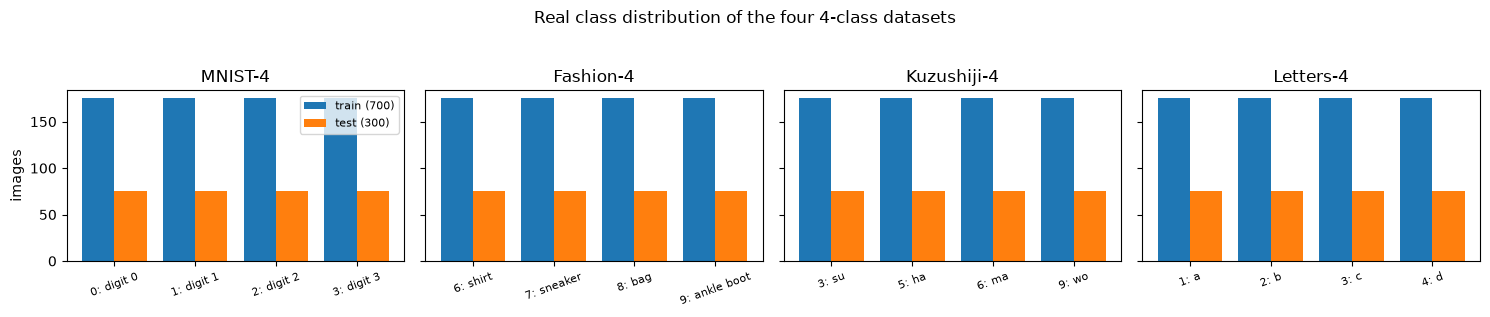

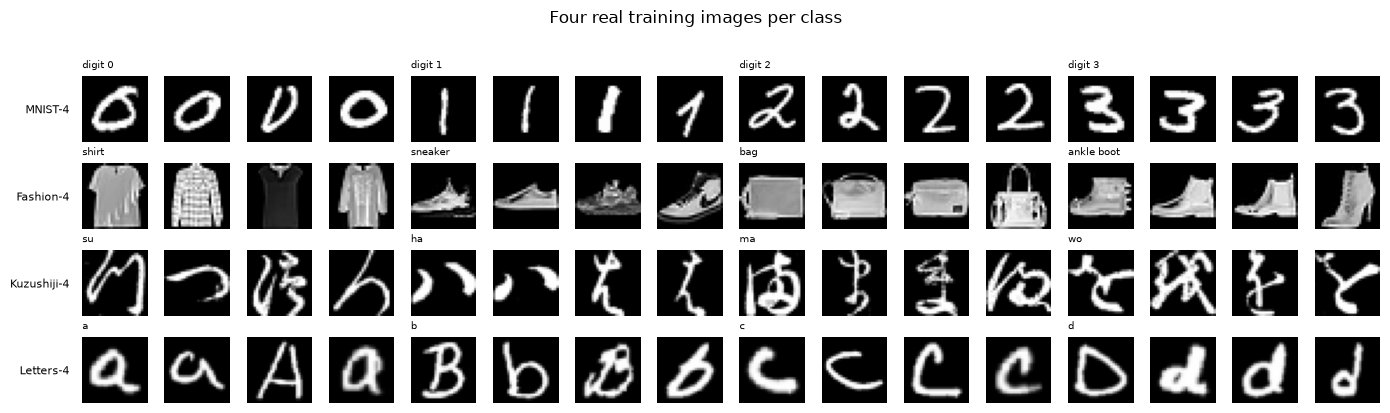

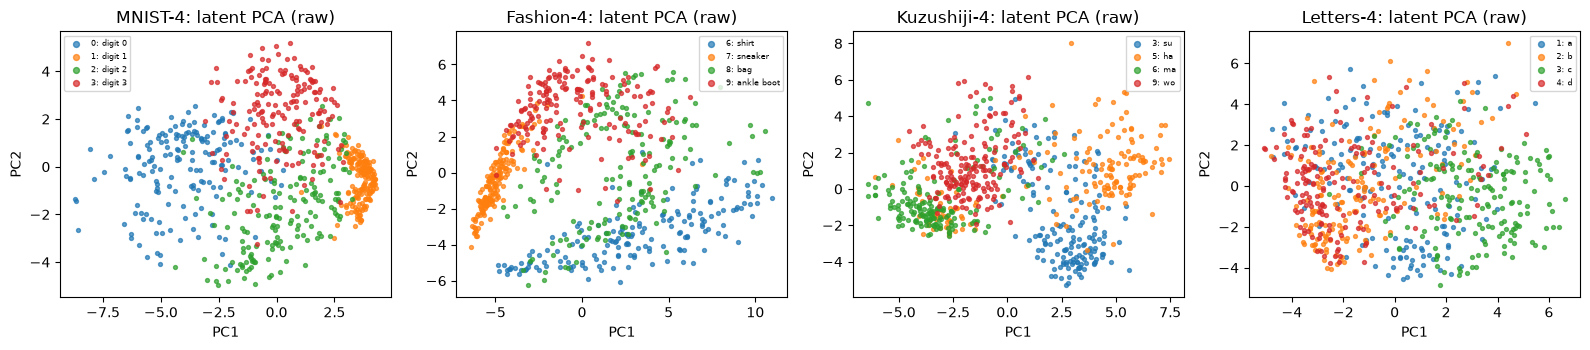

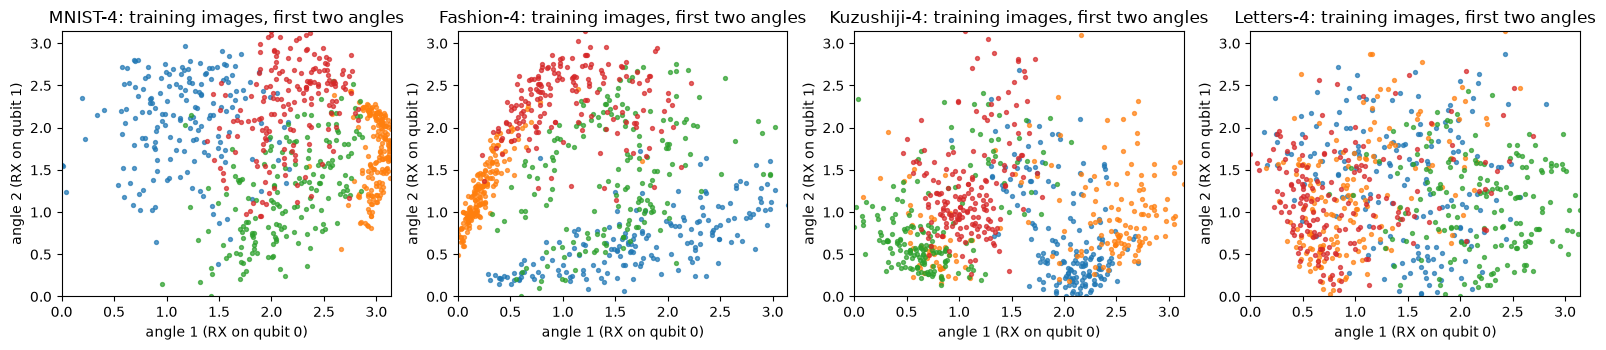

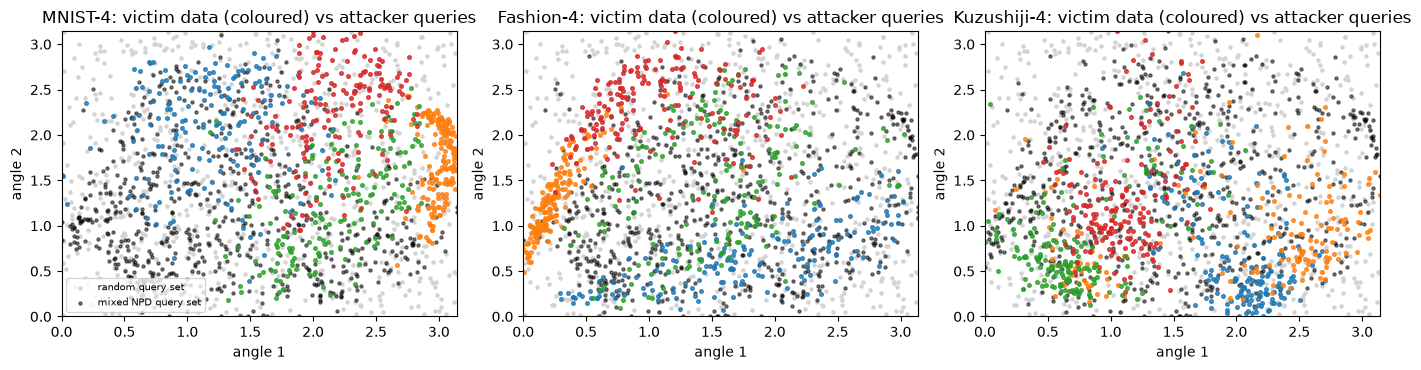

Letters-4 has no victim here; its encoded images only serve as non-problem-domain queries for the other three datasets.


In [6]:
DOM = build_domain(SEED)
FEATURE_NAMES = [f"latent_{i+1} (angle in [0, pi])" for i in range(N_FEATURES)]
print("Features per image (the d = 8 PCA components, scaled to rotation angles):", FEATURE_NAMES, "\n")
rows = []
for tname, d in DOM.items():
    src, cls = TASKS[tname]; names = CLASS_NAMES[src]
    full_n = len(SUBSETS[src][1])
    rows.append(dict(task=tname, source=src, original_labels={int(c): names[c] for c in cls}, images_in_file_subset=full_n,
                     task_samples=len(d["ytr"]) + len(d["yte"]), train_shape=d["ftr"].shape, test_shape=d["fte"].shape,
                     train_counts=np.bincount(d["ytr"]).tolist(), test_counts=np.bincount(d["yte"]).tolist(), unlabeled_pool=len(d["pool"])))
print(pd.DataFrame(rows).to_string(index=False))

# ---- class distribution of the real classes (bar chart) ----
fig, axes = plt.subplots(1, 4, figsize=(15, 3.0), sharey=True)
for ax, (tname, d) in zip(axes, DOM.items()):
    src, cls = TASKS[tname]; labs = [f"{c}: {CLASS_NAMES[src][c]}" for c in cls]; x = np.arange(len(cls))
    ax.bar(x - 0.2, np.bincount(d["ytr"]), 0.4, label="train (700)"); ax.bar(x + 0.2, np.bincount(d["yte"]), 0.4, label="test (300)")
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=20, fontsize=8); ax.set_title(tname)
axes[0].set_ylabel("images"); axes[0].legend(fontsize=8); plt.suptitle("Real class distribution of the four 4-class datasets", y=1.04); plt.tight_layout(); plt.show()

# ---- example images ----
fig, axes = plt.subplots(4, 16, figsize=(14, 4.0))
for r_, (tname, d) in enumerate(DOM.items()):
    src, cls = TASKS[tname]
    for ci in range(4):
        for k, i in enumerate(np.where(d["ytr"] == ci)[0][:4]):
            ax = axes[r_, ci * 4 + k]; ax.imshow(d["img_tr"][i], cmap="gray"); ax.axis("off")
            if k == 0: ax.set_title(CLASS_NAMES[src][cls[ci]], fontsize=7, loc="left")
    axes[r_, 0].text(-6, 14, tname, fontsize=8, ha="right", va="center")
plt.suptitle("Four real training images per class", y=1.02); plt.tight_layout(); plt.show()

# ---- 2-D scatter of real observations coloured by ground-truth label: (1) raw PCA coordinates of the autoencoder latents, (2) the first two rotation angles ----
cols = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (tname, d) in zip(axes, DOM.items()):
    src, cls = TASKS[tname]; pca2 = PCA(n_components=2, random_state=SEED).fit(d["ztr"]); P = pca2.transform(d["ztr"])      # PCA fitted on the training split only
    for ci in range(4): ax.scatter(P[d["ytr"] == ci, 0], P[d["ytr"] == ci, 1], s=8, color=cols[ci], alpha=0.7, label=f"{cls[ci]}: {CLASS_NAMES[src][cls[ci]]}")
    ax.set_title(f"{tname}: latent PCA (raw)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=6, markerscale=1.5)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (tname, d) in zip(axes, DOM.items()):
    src, cls = TASKS[tname]
    for ci in range(4): ax.scatter(d["ftr"][d["ytr"] == ci, 0], d["ftr"][d["ytr"] == ci, 1], s=8, color=cols[ci], alpha=0.7, label=f"{cls[ci]}: {CLASS_NAMES[src][cls[ci]]}")
    ax.set_title(f"{tname}: training images, first two angles"); ax.set_xlabel("angle 1 (RX on qubit 0)"); ax.set_ylabel("angle 2 (RX on qubit 1)"); ax.set_xlim(0, np.pi); ax.set_ylim(0, np.pi)
plt.tight_layout(); plt.show()

# ---- the attacker's query sets against the victim's own data (same two angles): unlabeled non-problem-domain images vs random features ----
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, tname in zip(axes, VICTIM_TASKS):
    d = DOM[tname]; src, cls = TASKS[tname]; Xm = query_set(DOM, tname, "mixed", N_QUERY, SEED); Xr = query_set(DOM, tname, "random", N_QUERY, SEED)
    ax.scatter(Xr[:, 0], Xr[:, 1], s=5, color="lightgrey", label="random query set"); ax.scatter(Xm[:, 0], Xm[:, 1], s=5, color="k", alpha=0.5, label="mixed NPD query set")
    for ci in range(4): ax.scatter(d["ftr"][d["ytr"] == ci, 0], d["ftr"][d["ytr"] == ci, 1], s=7, color=cols[ci], alpha=0.8)
    ax.set_title(f"{tname}: victim data (coloured) vs attacker queries"); ax.set_xlim(0, np.pi); ax.set_ylim(0, np.pi); ax.set_xlabel("angle 1"); ax.set_ylabel("angle 2")
axes[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()
print("Letters-4 has no victim here; its encoded images only serve as non-problem-domain queries for the other three datasets.")

## 2. The quantum building blocks and the simulated cloud devices

**Devices.** The paper runs `default.mixed` with custom noise to imitate NISQ hardware. We define three devices (parameters in the table printed below). After each logical gate, on every wire the gate touches, the noise channels
AmplitudeDamping $\to$ PhaseFlip $\to$ BitFlip $\to$ DepolarizingChannel are applied once per physical pulse ($H$: one $\sqrt X$ pulse, $R_X$: two, $R_Z$: virtual and noiseless, $CR_X$: two CNOTs), and the $\langle Z\rangle$ read-out is scaled by $1-2\varepsilon_{ro}$.
Because the paper does not give its parameters they are our choice, fixed before looking at any result, with different dominant error types so that moving a circuit from one device to another changes its outputs by a few percent.

**Simulator.** Everything is simulated exactly with density matrices. The encoding circuit and PQC-1 contain no entangling gate, so the state stays a product of $2 \times 2$ density matrices (any number of qubits is cheap);
PQC-6 / PQC-17 / PQC-19 use the full $16 \times 16$ density matrix. The next Section proves the agreement with PennyLane.

In [7]:
# ---------------------------------------------------------------- Kraus operators -> superoperators (row-major vec(rho))
I2 = np.eye(2, dtype=complex); PX = np.array([[0, 1], [1, 0]], dtype=complex); PY = np.array([[0, -1j], [1j, 0]], dtype=complex); PZ = np.diag([1, -1]).astype(complex)

def superop(kraus):
    """vec(K rho K^dag) = kron(K, conj(K)) vec(rho); a channel is the sum over its Kraus operators."""
    return sum(np.kron(K, K.conj()) for K in kraus)

def amplitude_damping(g): return superop([np.array([[1, 0], [0, np.sqrt(1 - g)]], dtype=complex), np.array([[0, np.sqrt(g)], [0, 0]], dtype=complex)])
def phase_flip(p):        return superop([np.sqrt(1 - p) * I2, np.sqrt(p) * PZ])
def bit_flip(p):          return superop([np.sqrt(1 - p) * I2, np.sqrt(p) * PX])
def depolarizing(p):      return superop([np.sqrt(1 - p) * I2, np.sqrt(p / 3) * PX, np.sqrt(p / 3) * PY, np.sqrt(p / 3) * PZ])   # PennyLane's DepolarizingChannel(p)

def rx_mat(a):
    a = np.asarray(a, dtype=float); c, s = np.cos(a / 2), np.sin(a / 2); U = np.zeros(a.shape + (2, 2), dtype=complex)
    U[..., 0, 0] = c; U[..., 1, 1] = c; U[..., 0, 1] = -1j * s; U[..., 1, 0] = -1j * s; return U
def rz_mat(a):
    a = np.asarray(a, dtype=float); U = np.zeros(a.shape + (2, 2), dtype=complex); U[..., 0, 0] = np.exp(-0.5j * a); U[..., 1, 1] = np.exp(0.5j * a); return U
H_MAT = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
def superop_unitary(U): return np.einsum("...ia,...jc->...ijac", U, U.conj()).reshape(U.shape[:-2] + (4, 4))

# ---------------------------------------------------------------- the simulated cloud devices
PULSES = {"h": 1, "rx": 2, "rz": 0, "crx": 2}   # CHOICE: noisy 'basis-gate' pulses per logical gate and wire: H = 1 sqrt(X) pulse, RX = 2, RZ is virtual (free), CRX = 2 CNOTs

class Device:
    """A simulated NISQ device ("custom noises such as readout error, amplitude damping, phase flip, depolarising and bit-flip error", Sec. 4.1).
    After every logical gate, on every wire the gate touches, the channel sequence AmplitudeDamping -> PhaseFlip -> BitFlip -> Depolarizing is applied
    PULSES[gate] times; <Z> read-outs are scaled by (1 - 2 * readout)."""
    def __init__(self, name, gamma=0.0, p_phase=0.0, p_bit=0.0, p_dep=0.0, readout=0.0):
        self.name, self.gamma, self.p_phase, self.p_bit, self.p_dep, self.readout = name, gamma, p_phase, p_bit, p_dep, readout
        one = depolarizing(p_dep) @ bit_flip(p_bit) @ phase_flip(p_phase) @ amplitude_damping(gamma)
        self._S = {g: (None if k == 0 or self.ideal else np.linalg.matrix_power(one, k)) for g, k in PULSES.items()}
    @property
    def ideal(self): return max(self.gamma, self.p_phase, self.p_bit, self.p_dep) == 0.0
    def S(self, gate): return self._S[gate]
    def apply_pennylane(self, wire, gate):
        for _ in range(PULSES[gate]):
            qml.AmplitudeDamping(self.gamma, wires=wire); qml.PhaseFlip(self.p_phase, wires=wire); qml.BitFlip(self.p_bit, wires=wire); qml.DepolarizingChannel(self.p_dep, wires=wire)

# CHOICE: the paper does not publish its noise parameters. Three devices with different error budgets and different dominant error types, fixed in advance
# (not tuned to the paper's numbers): the victim runs on Dev-A, the defences add Dev-B, the attacker trains its clone on Dev-C.
DEVICES = {"Dev-A": Device("Dev-A", gamma=0.010, p_phase=0.008, p_bit=0.004, p_dep=0.010, readout=0.03),
           "Dev-B": Device("Dev-B", gamma=0.020, p_phase=0.004, p_bit=0.010, p_dep=0.006, readout=0.05),
           "Dev-C": Device("Dev-C", gamma=0.015, p_phase=0.010, p_bit=0.006, p_dep=0.008, readout=0.04),
           "ideal": Device("ideal")}
DEV_A, DEV_B, DEV_C, IDEAL = DEVICES["Dev-A"], DEVICES["Dev-B"], DEVICES["Dev-C"], DEVICES["ideal"]
print(pd.DataFrame({k: dict(amp_damp=v.gamma, phase_flip=v.p_phase, bit_flip=v.p_bit, depolarizing=v.p_dep, readout=v.readout) for k, v in DEVICES.items()}).T.to_string())

# ---------------------------------------------------------------- product-state (qubit-wise) simulation: encoding and PQC-1 stay product states
def _apply(vec, S): return np.einsum("...ab,...b->...a", S, vec) if S.ndim > 2 else vec @ S.T

def encode_product(X, n, dev, seq, use_h=False):
    """Noisy angle encoding of X (N, n * len(seq)): optional Hadamard, then gate seq[k] with angle X[:, k*n + q] on qubit q. Returns (N, n, 4) vectorised 2x2 density matrices."""
    N = X.shape[0]; vec = np.zeros((N, n, 4), dtype=complex); vec[..., 0] = 1.0
    if use_h:
        vec = _apply(vec, superop_unitary(H_MAT))
        if dev.S("h") is not None: vec = _apply(vec, dev.S("h"))
    for k, g in enumerate(seq):
        U = rx_mat(X[:, k * n:(k + 1) * n]) if g == "rx" else rz_mat(X[:, k * n:(k + 1) * n])
        vec = _apply(vec, superop_unitary(U))
        if dev.S(g) is not None: vec = _apply(vec, dev.S(g))
    return vec

def pqc1_product(vec, theta, dev):
    """Sim et al. circuit 1 (RX(t) then RZ(t) on every qubit, no entanglement). theta: (layers, 2, n)."""
    for layer in theta:
        for g, ang in zip(("rx", "rz"), layer):
            S = superop_unitary(rx_mat(ang) if g == "rx" else rz_mat(ang))
            if dev.S(g) is not None: S = dev.S(g) @ S
            vec = _apply(vec, S)
    return vec

def z_from_product(vec, readout=0.0): return (vec[..., 0].real - vec[..., 3].real) * (1 - 2 * readout)

def product_to_full(vec):
    """(N, n, 4) -> (N, 2^n, 2^n) density matrices (qubit 0 = most significant, as in PennyLane)."""
    N, n, _ = vec.shape; rho = vec[:, 0].reshape(N, 2, 2)
    for q in range(1, n):
        r = vec[:, q].reshape(N, 2, 2); rho = np.einsum("nab,ncd->nacbd", rho, r).reshape(N, rho.shape[1] * 2, rho.shape[2] * 2)
    return rho

# ---------------------------------------------------------------- full density matrices (entangling circuits)
def full_apply_S(rho, S, q, n):
    N = rho.shape[0]; L, M = 2 ** q, 2 ** (n - q - 1)
    t = np.tensordot(rho.reshape(N, L, 2, M, L, 2, M), S.reshape(2, 2, 2, 2), axes=([2, 5], [2, 3]))
    return t.transpose(0, 1, 5, 2, 3, 6, 4).reshape(N, 2 ** n, 2 ** n)

def crx_unitary(angle, c, t, n):
    D = 2 ** n; idx = np.arange(D); P1 = np.diag(((idx >> (n - 1 - c)) & 1).astype(float))
    return (np.eye(D) - P1) + P1 @ np.kron(np.kron(np.eye(2 ** t), rx_mat(angle)), np.eye(2 ** (n - t - 1)))

def pqc_ops(name, n=4):
    """Gate list of the PQC; each op is (gate, wires, parameter index). # CHOICE: reconstructed from the description of Sim, Johnson and Aspuru-Guzik (2019):
    PQC-1 = RX, RZ on every qubit; PQC-6 = RX,RZ, CRX between all ordered pairs, RX,RZ; PQC-17 = RX,RZ, CRX on (1->0), (3->2), (2->1);
    PQC-19 = RX,RZ, CRX around a ring. The paper only names the circuits, so the exact CRX orderings are assumptions."""
    ops, k = [], 0
    def rot():
        nonlocal k
        for q in range(n): ops.append(("rx", (q,), k)); k += 1; ops.append(("rz", (q,), k)); k += 1
    def crx(c, t):
        nonlocal k
        ops.append(("crx", (c, t), k)); k += 1
    rot()
    if name == "PQC-6":
        for t in range(n - 1, -1, -1):
            for c in range(n - 1, -1, -1):
                if c != t: crx(c, t)
        rot()
    elif name == "PQC-17":
        for c, t in [(1, 0), (3, 2), (2, 1)]:
            if max(c, t) < n: crx(c, t)
    elif name == "PQC-19":
        for q in range(n - 1, -1, -1): crx(q, (q - 1) % n)
    elif name != "PQC-1":
        raise ValueError(name)
    return ops, k

def run_pqc_full(rho, ops, theta, dev, n):
    for g, w, k in ops:
        if g == "crx":
            U = crx_unitary(theta[k], w[0], w[1], n); rho = U @ rho @ U.conj().T
            if dev.S("crx") is not None:
                for q in w: rho = full_apply_S(rho, dev.S("crx"), q, n)
        else:
            S = superop_unitary(rx_mat(theta[k]) if g == "rx" else rz_mat(theta[k]))
            if dev.S(g) is not None: S = dev.S(g) @ S
            rho = full_apply_S(rho, S, w[0], n)
    return rho

def z_from_full(rho, n, readout=0.0):
    D = 2 ** n; probs = np.einsum("nii->ni", rho).real
    bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
    return (probs @ (1 - 2 * bits)) * (1 - 2 * readout)

for name in ("PQC-1", "PQC-17", "PQC-19", "PQC-6"):
    ops, k = pqc_ops(name, 4); print(f"{name}: {len(ops)} gates, {k} trainable parameters ({sum(o[0]=='crx' for o in ops)} controlled-RX)")

       amp_damp  phase_flip  bit_flip  depolarizing  readout
Dev-A     0.010       0.008     0.004         0.010     0.03
Dev-B     0.020       0.004     0.010         0.006     0.05
Dev-C     0.015       0.010     0.006         0.008     0.04
ideal     0.000       0.000     0.000         0.000     0.00


PQC-1: 8 gates, 8 trainable parameters (0 controlled-RX)
PQC-17: 11 gates, 11 trainable parameters (3 controlled-RX)
PQC-19: 12 gates, 12 trainable parameters (4 controlled-RX)
PQC-6: 28 gates, 28 trainable parameters (12 controlled-RX)


**The model, the training loop and the cloud service.** `QNN` is the hybrid network of Fig. 1: noisy angle encoding (fixed) $\to$ PQC (trainable) $\to$ $\langle Z\rangle$ of every qubit $\to$ linear layer. `train_qnn` runs Adam on all weights; the circuit gradient is a **SPSA** estimate
$g \approx \frac{L(\theta + c\Delta) - L(\theta - c\Delta)}{2c}\,\Delta$ (two circuit evaluations per step, random signs $\Delta$, $c = 0.1$ rad), because backpropagation is not available on real hardware, and the linear layer uses its exact gradient. The loss is a cross-entropy with targets
that are one-hot (Top-1: the NLL loss of the paper) or the victim's probability vector (Top-k: the paper's KL divergence, which has the same gradient). `Oracle` is the cloud API: each query goes to one member (a QNN on a device) chosen at random, and the answer is a probability vector computed from finite-shot estimates of the $\langle Z\rangle$ values.

In [8]:
ENC_PATTERN, ENC_H = ("rx", "rz"), False      # encoding gate pattern and Hadamard flag; CHOICE: confirmed on a validation split in Section 2.2

def slot_seq(n, pattern=None):
    """Gate sequence of the angle encoding for n qubits: the 8 features fill the qubits slot by slot (n=2: 4 slots, n=4: 2 slots, n=8: 1 slot)."""
    pattern = pattern or ENC_PATTERN
    return tuple(pattern[k % 2] for k in range(N_FEATURES // n))

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def soft_ce(logits, T):
    """Cross-entropy with (possibly soft) targets T; for one-hot T it is the NLL loss, for probability vectors it equals KLDiv + a constant."""
    return float(-(T * np.log(softmax(logits) + 1e-12)).sum(1).mean())

class Adam:
    def __init__(self, shape, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(shape); self.v = np.zeros(shape); self.t = 0; self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
    def step(self, g):
        self.t += 1; self.m = self.b1 * self.m + (1 - self.b1) * g; self.v = self.b2 * self.v + (1 - self.b2) * g * g
        return self.lr * (self.m / (1 - self.b1 ** self.t)) / (np.sqrt(self.v / (1 - self.b2 ** self.t)) + self.eps)

class Enc:
    """Noisy encoded states of a set of samples on one device: per-qubit vectors always, full density matrices on demand."""
    def __init__(self, X, n, dev, pattern=None, use_h=None):
        self.n, self.dev = n, dev; self.vec = encode_product(X, n, dev, slot_seq(n, pattern), ENC_H if use_h is None else use_h); self._full = None
    def full(self):
        if self._full is None: self._full = product_to_full(self.vec)
        return self._full
    def take(self, idx):
        e = object.__new__(Enc); e.n, e.dev, e.vec = self.n, self.dev, self.vec[idx]; e._full = None if self._full is None else self._full[idx]; return e

class QNN:
    """Hybrid QNN of Fig. 1: noisy angle encoding (fixed) -> PQC (trainable) -> <Z> of every qubit -> classical linear layer (n -> classes)."""
    def __init__(self, pqc, n, n_classes, dev, rng):
        self.pqc, self.n, self.C, self.dev = pqc, n, n_classes, dev
        self.ops, self.n_params = pqc_ops(pqc, n)
        self.theta = rng.uniform(0, 2 * np.pi, self.n_params)                    # CHOICE: random circuit weights in [0, 2 pi)
        bound = 1 / np.sqrt(n)                                                   # torch.nn.Linear's default initialisation
        self.W = rng.uniform(-bound, bound, (n, n_classes)); self.b = rng.uniform(-bound, bound, n_classes)
    def z(self, enc, theta=None, dev=None):
        theta = self.theta if theta is None else theta; dev = dev or self.dev
        if self.pqc == "PQC-1":
            th = np.zeros((1, 2, self.n))
            for g, w, k in self.ops: th[0, 0 if g == "rx" else 1, w[0]] = theta[k]
            return z_from_product(pqc1_product(enc.vec, th, dev), dev.readout)
        return z_from_full(run_pqc_full(enc.full(), self.ops, theta, dev, self.n), self.n, dev.readout)
    def logits(self, enc, theta=None, dev=None): return self.z(enc, theta, dev) @ self.W + self.b
    def predict(self, enc, dev=None): return self.logits(enc, dev=dev).argmax(1)

def train_qnn(model, enc_tr, T_tr, enc_te, y_te, epochs, seed, lr=LR, batch=BATCH, spsa_c=SPSA_C, dev=None):
    """Adam on all weights. The circuit gradient is a SPSA estimate (two circuit evaluations per step, Rademacher perturbation of size spsa_c);
    the linear layer uses its exact gradient. T_tr are the training targets (one-hot for hard labels, probability vectors for Top-k).
    Test accuracy and test NLL (against the true labels) are recorded after every epoch."""
    r = np.random.default_rng(seed); N = len(T_tr); dev = dev or model.dev
    opt_t, opt_w, opt_b = Adam(model.theta.shape, lr), Adam(model.W.shape, lr), Adam(model.b.shape, lr)
    Y_te = np.eye(model.C)[y_te]; hist = {"epoch": [], "test_acc": [], "test_loss": []}
    def log(ep):
        lg = model.logits(enc_te, dev=dev); hist["epoch"].append(ep); hist["test_acc"].append(float((lg.argmax(1) == y_te).mean())); hist["test_loss"].append(soft_ce(lg, Y_te))
    log(0)
    for ep in range(1, epochs + 1):
        perm = r.permutation(N)
        for s in range(0, N, batch):
            idx = perm[s:s + batch]; e = enc_tr.take(idx); T = T_tr[idx]
            delta = r.choice([-1.0, 1.0], model.theta.shape)
            lp = soft_ce(model.logits(e, model.theta + spsa_c * delta, dev), T); lm = soft_ce(model.logits(e, model.theta - spsa_c * delta, dev), T)
            g_theta = (lp - lm) / (2 * spsa_c) * delta                          # SPSA (for Rademacher perturbations 1/delta = delta)
            z = model.z(e, dev=dev); p = softmax(z @ model.W + model.b); p = (p - T) / len(idx)
            model.W -= opt_w.step(z.T @ p); model.b -= opt_b.step(p.sum(0)); model.theta -= opt_t.step(g_theta)
        log(ep)
    return hist

def confusion(y, p, C=4):
    M = np.zeros((C, C), dtype=int)
    for a, b in zip(y, p): M[a, b] += 1
    return M

# ---------------------------------------------------------------- the cloud service: the victim as a black-box API
def shot_z(z, shots, r):
    """Finite-shot estimate of <Z> for each qubit: 1 - 2 * (number of '1' outcomes) / shots."""
    return 1 - 2 * r.binomial(shots, np.clip((1 - z) / 2, 0, 1)) / shots

class Oracle:
    """QMLaaS endpoint. `members` = list of (QNN, Device). Every query is routed to one member chosen uniformly at random (50 % each for two members:
    HVIP uses one QNN on two devices, HAVIP two QNNs on two devices; a single member is the undefended service). Returns the softmax probability vector;
    Top-1 service = argmax of it. Shot noise (SHOTS) is added to the <Z> values, as for a real device; exact=True switches it off."""
    def __init__(self, members, seed=0, shots=SHOTS):
        self.members, self.seed, self.shots, self.calls = members, seed, shots, 0
    def probs(self, X, exact=False):
        self.calls += 1; r = np.random.default_rng([self.seed, self.calls]); outs = []
        for m, dev in self.members:
            z = m.z(Enc(X, m.n, dev), dev=dev)
            if not exact and self.shots: z = shot_z(z, self.shots, r)
            outs.append(softmax(z @ m.W + m.b))
        route = r.integers(0, len(self.members), len(X)); P = np.stack(outs)[route, np.arange(len(X))]
        return P

### 2.1 Which encoding order? A validation check on training data only

"Angle encoding with $R_Z$ gates, two features per qubit" leaves the order open. A lone $R_Z$ on $\lvert 0\rangle$ changes nothing, so the first rotation needs either a Hadamard before it or a different axis. Because PQC-1 only contains $R_X$ and $R_Z$ rotations,
a feature stored in the X-component of the qubit's Bloch vector can be invisible to the Z read-out. We therefore train the undefended victim with each of three plausible encodings on a **validation split of the training data** (60 % / 40 % of the 700 training samples; the test set is untouched)
and use the best one for everything that follows (a `# CHOICE`).

In [9]:
ENCODINGS = {"H, RZ, RX": (("rz", "rx"), True), "H, RX, RZ": (("rx", "rz"), True), "RX, RZ (no H)": (("rx", "rz"), False)}
rows = []
for tname in VICTIM_TASKS:
    for sd in SEEDS[:2]:
        tk = build_domain(sd)[tname]
        ia, iv = train_test_split(np.arange(len(tk["ytr"])), test_size=0.4, stratify=tk["ytr"], random_state=sd)       # validation split of the TRAINING data only
        for ename, (pat, use_h) in ENCODINGS.items():
            ea, ev = Enc(tk["ftr"][ia], 4, DEV_A, pat, use_h), Enc(tk["ftr"][iv], 4, DEV_A, pat, use_h)
            m = QNN("PQC-1", 4, 4, DEV_A, np.random.default_rng(sd))
            h = train_qnn(m, ea, np.eye(4)[tk["ytr"][ia]], ev, tk["ytr"][iv], EPOCHS, sd, dev=DEV_A)
            rows.append(dict(task=tname, seed=sd, encoding=ename, val_acc=h["test_acc"][-1]))
enc_tab = pd.DataFrame(rows).pivot_table(index="encoding", columns="task", values="val_acc", aggfunc="mean"); enc_tab["mean"] = enc_tab.mean(axis=1)
print("Validation accuracy (PQC-1 victim on Dev-A, trained on 60 % of the training data, scored on the other 40 %; the test set is untouched):")
print((enc_tab * 100).round(1).to_string())
BEST_ENC = enc_tab["mean"].idxmax(); ENC_PATTERN, ENC_H = ENCODINGS[BEST_ENC]       # CHOICE: encoding order picked on validation data
print(f"\nCHOICE: encoding = {BEST_ENC}  (pattern {ENC_PATTERN}, Hadamard first: {ENC_H})")

Validation accuracy (PQC-1 victim on Dev-A, trained on 60 % of the training data, scored on the other 40 %; the test set is untouched):
task           Fashion-4  Kuzushiji-4  MNIST-4  mean
encoding                                            
H, RX, RZ           45.4         35.7     39.3  40.1
H, RZ, RX           58.9         54.6     43.6  52.4
RX, RZ (no H)       90.4         77.1     86.8  84.8

CHOICE: encoding = RX, RZ (no H)  (pattern ('rx', 'rz'), Hadamard first: False)


## Quantum Circuit Architecture

Every gate-based model that is trained or evaluated in this notebook is a PennyLane QNode on `default.mixed`: the *same gate list* (`pqc_ops`, `slot_seq`) feeds both the QNode and the NumPy simulator that does the training. The cell below compares them numerically
(entire output density matrices and $\langle Z\rangle$ values, random inputs and weights) for every distinct architecture (PQC-1 on 2, 4 and 8 qubits, PQC-17, PQC-19, PQC-6 on 4 qubits) on all three devices and on an ideal device, and asserts that the largest difference is below $10^{-10}$.
Then each architecture is **drawn** from the QNode, with qubit count, circuit depth and number of trainable parameters. The paper omits the circuit details beyond the circuit number and Fig. 1; the assumptions (CR$_X$ orderings, encoding order, noise insertion) are listed in the table at the top and in the code comments.

In [10]:
def build_qnode(pqc, n, dev=None, barrier=True):
    """The PennyLane QNode (default.mixed, as in the paper) of the quantum part of a QNN: noisy angle encoding -> PQC -> Pauli-Z read-out.
    It is built from the SAME gate list (pqc_ops, slot_seq, ENC_H) that the NumPy simulator executes. With a Device, its noise channels are inserted
    after every gate on every wire the gate touches (PULSES times); the <Z> read-out error is applied classically afterwards."""
    ops, _ = pqc_ops(pqc, n); seq = slot_seq(n)
    def noisy(wires, gate):
        if dev is not None and not dev.ideal:
            for w in wires: dev.apply_pennylane(w, gate)
    @qml.qnode(qml.device("default.mixed", wires=n))
    def circuit(x, theta, dm=False):
        if ENC_H:
            for q in range(n): qml.Hadamard(wires=q); noisy([q], "h")
        for kk, g in enumerate(seq):
            for q in range(n): (qml.RX if g == "rx" else qml.RZ)(x[kk * n + q], wires=q); noisy([q], g)
        if barrier: qml.Barrier(wires=range(n))          # only a visual separator between encoding and PQC in the drawings
        for g, w, k in ops:
            if g == "rx": qml.RX(theta[k], wires=w[0])
            elif g == "rz": qml.RZ(theta[k], wires=w[0])
            else: qml.CRX(theta[k], wires=list(w))
            noisy(w, g)
        if dm: return qml.density_matrix(list(range(n)))
        return [qml.expval(qml.PauliZ(q)) for q in range(n)]
    return circuit

def simulate(pqc, n, X, theta, dev):
    """Density matrices and <Z> (without read-out error) from the NumPy simulator that is used for all training."""
    e = Enc(X, n, dev)
    if pqc == "PQC-1":
        th = np.zeros((1, 2, n)); ops, _ = pqc_ops(pqc, n)
        for g, w, k in ops: th[0, 0 if g == "rx" else 1, w[0]] = theta[k]
        vec = pqc1_product(e.vec, th, dev); return product_to_full(vec), z_from_product(vec)
    ops, _ = pqc_ops(pqc, n); rho = run_pqc_full(e.full(), ops, theta, dev, n); return rho, z_from_full(rho, n)

ARCHS = [("PQC-1", 2), ("PQC-1", 4), ("PQC-1", 8), ("PQC-17", 4), ("PQC-19", 4), ("PQC-6", 4)]
r = np.random.default_rng(0); rows = []
for pqc, n in ARCHS:
    _, kp = pqc_ops(pqc, n); X = r.uniform(0, np.pi, (3, N_FEATURES)); theta = r.uniform(0, 2 * np.pi, kp)
    for dname, dev in DEVICES.items():
        circ = build_qnode(pqc, n, dev); rho_sim, z_sim = simulate(pqc, n, X, theta, dev)
        d_rho = max(np.abs(np.array(circ(X[i], theta, dm=True)) - rho_sim[i]).max() for i in range(len(X)))
        d_z = max(np.abs(np.array(circ(X[i], theta)) - z_sim[i]).max() for i in range(len(X)))
        rows.append(dict(circuit=pqc, qubits=n, device=dname, max_diff_density_matrix=d_rho, max_diff_expval_Z=d_z))
chk = pd.DataFrame(rows)
print(chk.to_string(index=False, float_format=lambda v: f"{v:.1e}"))
assert chk.max_diff_density_matrix.max() < 1e-10 and chk.max_diff_expval_Z.max() < 1e-10, "NumPy simulator disagrees with PennyLane default.mixed"
print(f"\nOK: the NumPy simulator used for training equals the PennyLane default.mixed QNode (all {len(ARCHS)} circuits x {len(DEVICES)} devices), max difference {max(chk.max_diff_density_matrix.max(), chk.max_diff_expval_Z.max()):.1e}")

circuit  qubits device  max_diff_density_matrix  max_diff_expval_Z
  PQC-1       2  Dev-A                  5.6e-13            5.0e-13
  PQC-1       2  Dev-B                  5.2e-13            4.5e-13
  PQC-1       2  Dev-C                  5.4e-13            4.7e-13
  PQC-1       2  ideal                  5.6e-16            4.4e-16
  PQC-1       4  Dev-A                  4.4e-13            9.9e-13
  PQC-1       4  Dev-B                  4.1e-13            9.3e-13
  PQC-1       4  Dev-C                  4.2e-13            9.6e-13
  PQC-1       4  ideal                  1.3e-16            2.2e-16
  PQC-1       8  Dev-A                  2.6e-13            2.1e-12
  PQC-1       8  Dev-B                  2.2e-13            1.9e-12
  PQC-1       8  Dev-C                  2.4e-13            2.0e-12
  PQC-1       8  ideal                  8.4e-17            4.4e-16
 PQC-17       4  Dev-A                  6.4e-13            1.4e-12
 PQC-17       4  Dev-B                  5.4e-13            1.3

Matplotlib is building the font cache; this may take a moment.


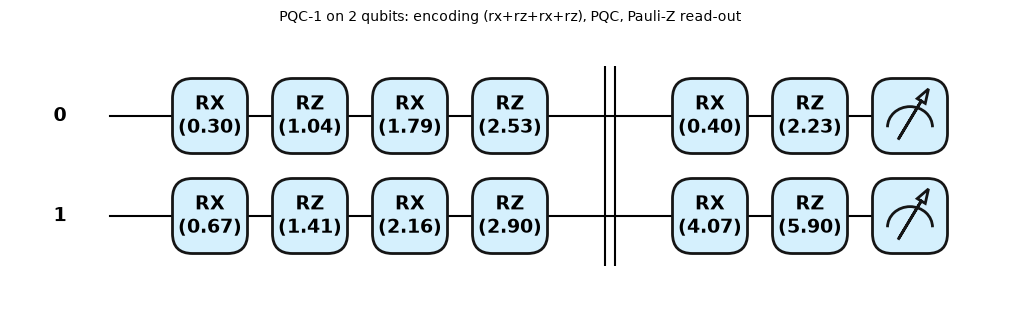

Matplotlib is building the font cache; this may take a moment.


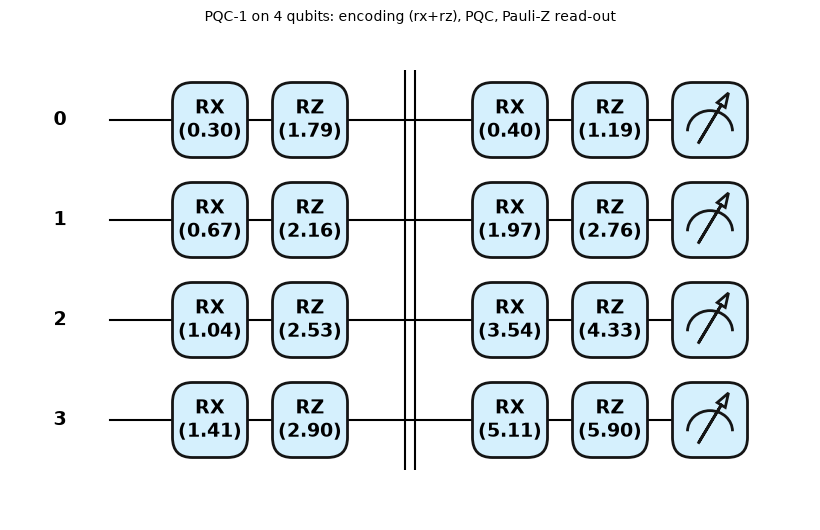

Matplotlib is building the font cache; this may take a moment.


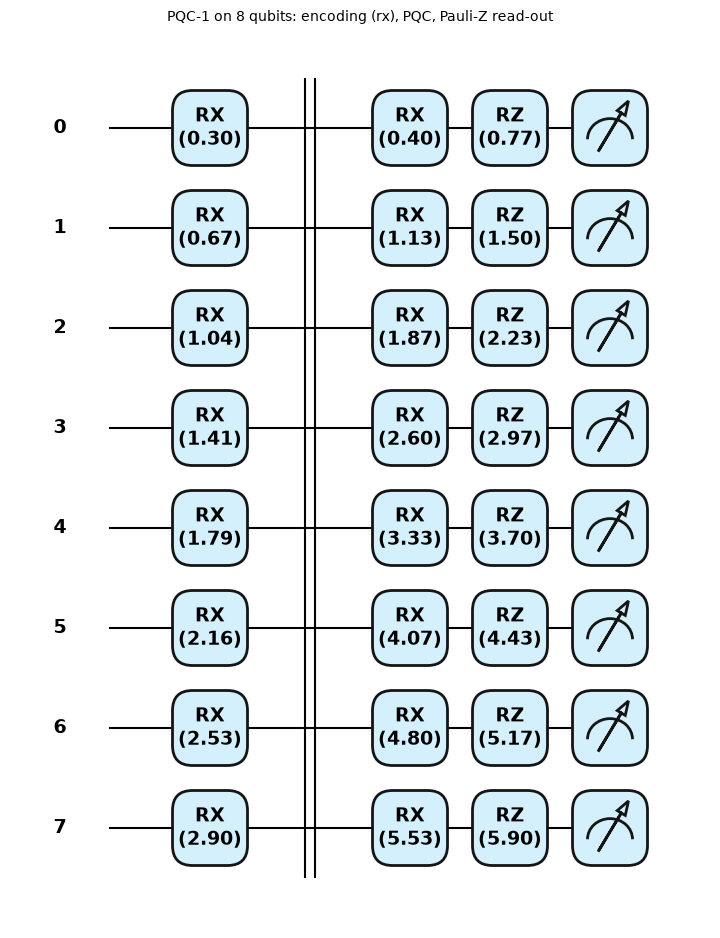

Matplotlib is building the font cache; this may take a moment.


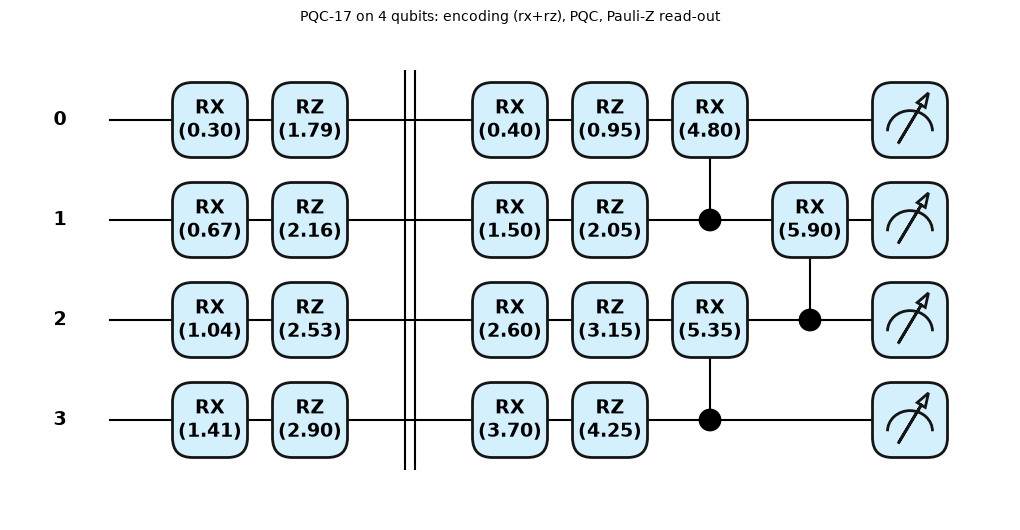

Matplotlib is building the font cache; this may take a moment.


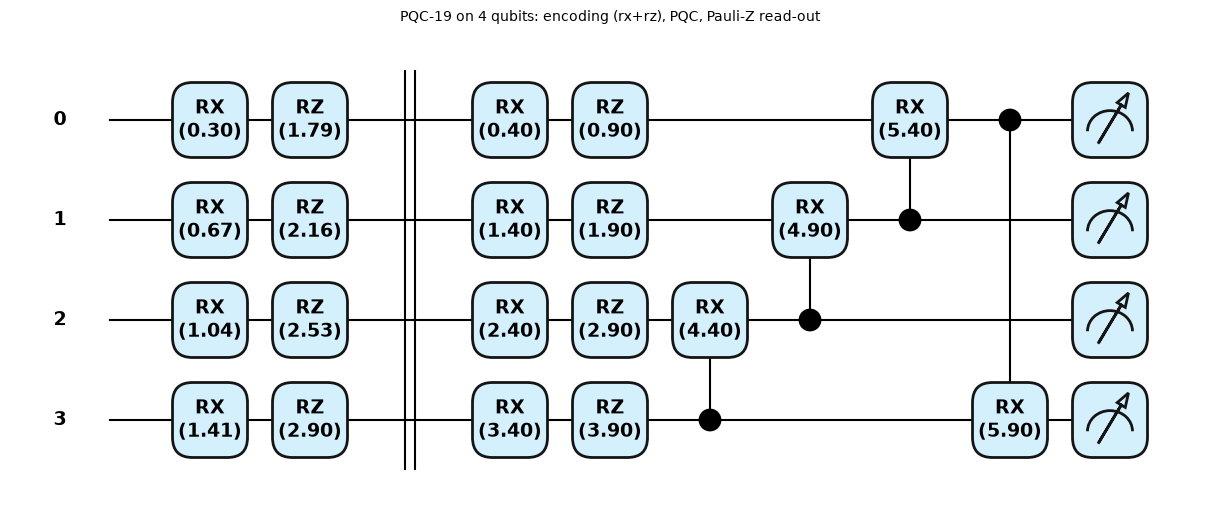

Matplotlib is building the font cache; this may take a moment.


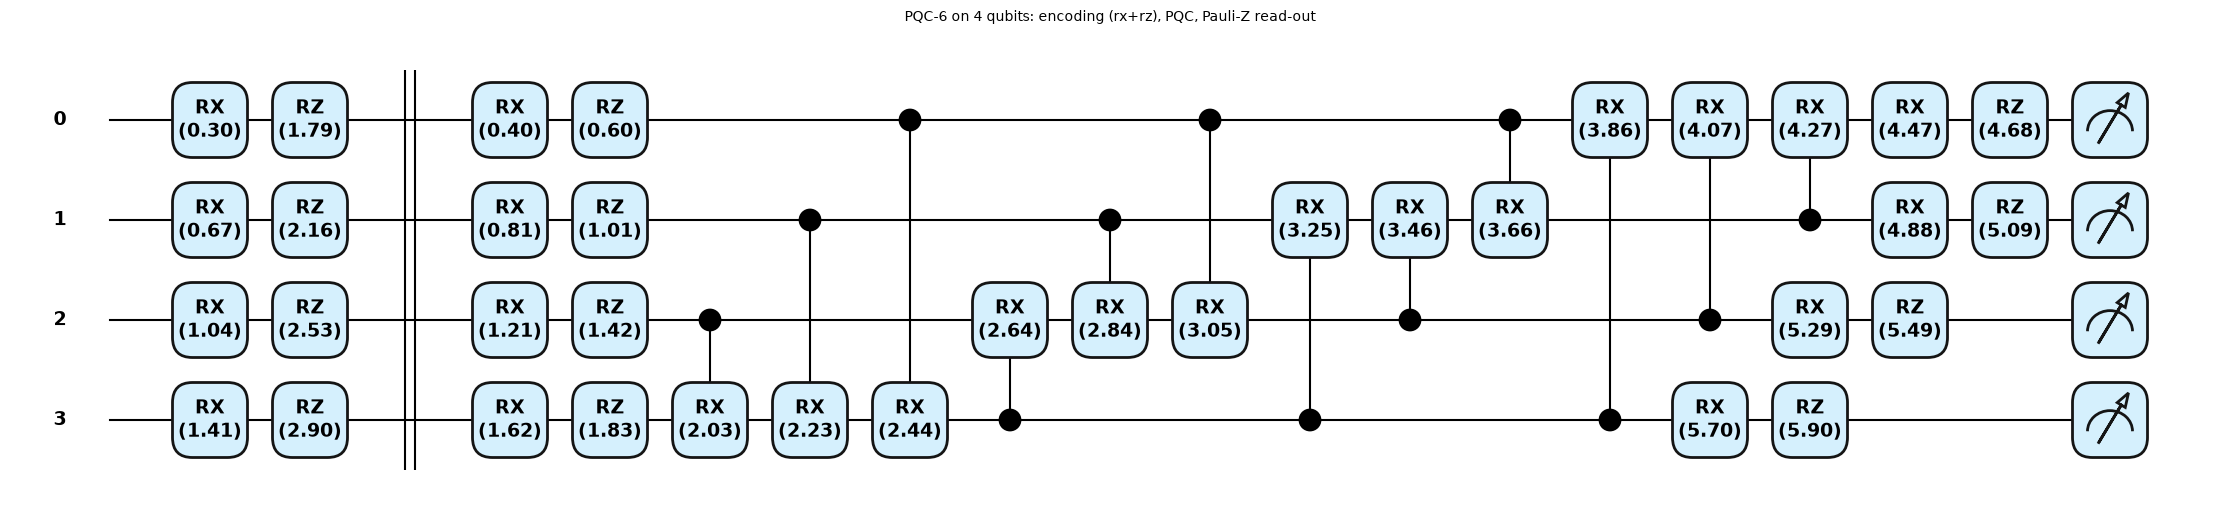

circuit  qubits  encoding_gates  pqc_gates  controlled_RX  depth  circuit_parameters  linear_layer_parameters  trainable_total
  PQC-1       2               8          4              0      6                   4                       12               16
  PQC-1       4               8          8              0      4                   8                       20               28
  PQC-1       8               8         16              0      3                  16                       36               52
 PQC-17       4               8         11              3      6                  11                       20               31
 PQC-19       4               8         12              4      8                  12                       20               32
  PQC-6       4               8         28             12     17                  28                       20               48

Noise insertion (Dev-A, 2 qubits, first encoding gates only) as a PennyLane text drawing: each logical gate is

In [11]:
fig_specs = []
r = np.random.default_rng(1); rows = []
for pqc, n in ARCHS:
    ops, kp = pqc_ops(pqc, n); circ = build_qnode(pqc, n)
    x0, th0 = np.linspace(0.3, 2.9, N_FEATURES), np.linspace(0.4, 5.9, kp)
    fig, ax = qml.draw_mpl(circ, decimals=2, style="pennylane")(x0, th0)
    fig.suptitle(f"{pqc} on {n} qubits: encoding ({'+'.join(slot_seq(n))}{' after H' if ENC_H else ''}), PQC, Pauli-Z read-out", y=1.02, fontsize=10); plt.show()
    depth = qml.specs(build_qnode(pqc, n, barrier=False))(x0, th0).resources.depth        # depth of the executed gates (the barrier is not a gate)
    rows.append(dict(circuit=pqc, qubits=n, encoding_gates=n * len(slot_seq(n)) + (n if ENC_H else 0), pqc_gates=len(ops), controlled_RX=sum(o[0] == "crx" for o in ops),
                     depth=depth, circuit_parameters=kp, linear_layer_parameters=n * 4 + 4, trainable_total=kp + n * 4 + 4))
print(pd.DataFrame(rows).to_string(index=False))
print("\nNoise insertion (Dev-A, 2 qubits, first encoding gates only) as a PennyLane text drawing: each logical gate is followed by its error channels on every wire it touches.")
print(qml.draw(build_qnode("PQC-1", 2, DEVICES["Dev-A"]), max_length=150, decimals=3)(np.linspace(0.3, 2.9, N_FEATURES), np.linspace(0.4, 5.9, 4)).split("\n\n")[0][:1400])

## 3. The victim, the attack and Table 1 / Fig. 4

**Victim.** PQC-1 on 4 qubits, trained for 25 epochs on Dev-A on the 700 training samples. **Attack.** The attacker builds the mixed NPD query set (700 unlabeled queries), sends it to the cloud and receives the Top-1 label or the Top-k vector of each query (with 1000-shot noise);
it then trains a clone (also PQC-1 on 4 qubits unless noted, **on Dev-C**) on the pairs (query, answer) for 25 epochs and is scored on the victim's 300 test images with their true labels. The tables also give **fidelity**, the share of test images on which the clone predicts the same class as the undefended victim.
Classical models on the same 8 inputs show what a model-agnostic attacker could do with the same queries.

In [12]:
EPOCHS_STAGE2 = 5         # CHOICE: HVIP victim = (EPOCHS - 5) epochs on Dev-A, then 5 epochs on Dev-B ("most epochs on one device, fewer on another", Sec. 4.3)

VICTIMS = {}
def get_victim(tname, seed, kind="base"):
    """kind 'base': PQC-1 trained on Dev-A. 'hvip': the same, then fine-tuned on Dev-B. 'qnn2': a PQC-19 QNN trained on Dev-B (HAVIP's second model)."""
    key = (tname, seed, kind)
    if key in VICTIMS: return VICTIMS[key]
    tk = build_domain(seed)[tname]; Ttr = np.eye(4)[tk["ytr"]]
    pqc, dev = ("PQC-19", DEV_B) if kind == "qnn2" else ("PQC-1", DEV_A)
    m = QNN(pqc, N_QUBITS, 4, dev, np.random.default_rng(seed + 11))
    if kind == "hvip":
        h1 = train_qnn(m, Enc(tk["ftr"], 4, DEV_A), Ttr, Enc(tk["fte"], 4, DEV_A), tk["yte"], EPOCHS - EPOCHS_STAGE2, seed + 12, dev=DEV_A)
        h2 = train_qnn(m, Enc(tk["ftr"], 4, DEV_B), Ttr, Enc(tk["fte"], 4, DEV_B), tk["yte"], EPOCHS_STAGE2, seed + 13, dev=DEV_B)
        hist = {k: h1[k] + h2[k][1:] for k in h1}; hist["epoch"] = list(range(len(hist["test_acc"])))   # stage 1 is scored on Dev-A, stage 2 on Dev-B
    else:
        hist = train_qnn(m, Enc(tk["ftr"], 4, dev), Ttr, Enc(tk["fte"], 4, dev), tk["yte"], EPOCHS, seed + 12, dev=dev)
    VICTIMS[key] = (m, hist)
    return VICTIMS[key]

def victim_test_acc(m, tk, dev):
    return float((m.predict(Enc(tk["fte"], 4, dev), dev=dev) == tk["yte"]).mean())

def make_oracle(tname, seed, defence="none"):
    """The cloud service. 'none': the victim always runs on Dev-A. 'hvip': one QNN, each query on Dev-A or Dev-B (50 %). 'havip': two QNNs
    (PQC-1 on Dev-A, PQC-19 on Dev-B), each query answered by one of them (50 %)."""
    if defence == "none":  return Oracle([(get_victim(tname, seed)[0], DEV_A)], seed=seed)
    if defence == "hvip":  v = get_victim(tname, seed, "hvip")[0]; return Oracle([(v, DEV_A), (v, DEV_B)], seed=seed)
    if defence == "havip": return Oracle([(get_victim(tname, seed)[0], DEV_A), (get_victim(tname, seed, "qnn2")[0], DEV_B)], seed=seed)
    raise ValueError(defence)

def make_baseline(tname, seed, defence):
    """The undefended reference of Table 2: the SAME model(s) of the defence's first member, always executed on Dev-A."""
    return Oracle([(get_victim(tname, seed, "hvip" if defence == "hvip" else "base")[0], DEV_A)], seed=seed)

def steal(oracle, Xq, mode, tname, seed, clone_pqc="PQC-1", clone_n=N_QUBITS, clone_dev=None, epochs=None, flip=0.0):
    """Model-stealing attack (Fig. 2): query the oracle with Xq, keep the Top-1 label ('top1') or the probability vector ('topk'), train a clone QNN on
    (Xq, answers) on the attacker's own device, then evaluate it on the victim's test set. Returns accuracy / NLL against the true labels,
    fidelity (agreement with the undefended victim) and the learning curve."""
    clone_dev = clone_dev or DEV_C; tk = build_domain(seed)[tname]
    P = oracle.probs(Xq)
    lab = P.argmax(1).copy()
    if flip:                                     # extra synthetic perturbation of the Top-1 answers (control experiment of Section 7): a random wrong class
        r_ = np.random.default_rng(seed + 31); hit = r_.random(len(lab)) < flip; lab[hit] = (lab[hit] + r_.integers(1, 4, hit.sum())) % 4
    T = np.eye(4)[lab] if mode == "top1" else P
    clone = QNN(clone_pqc, clone_n, 4, clone_dev, np.random.default_rng(seed + 21))
    enc_q, enc_te = Enc(Xq, clone_n, clone_dev), Enc(tk["fte"], clone_n, clone_dev)
    h = train_qnn(clone, enc_q, T, enc_te, tk["yte"], epochs or EPOCHS, seed + 22, dev=clone_dev)
    pred = clone.predict(enc_te, dev=clone_dev)
    ref = get_victim(tname, seed)[0]; ref_pred = ref.predict(Enc(tk["fte"], 4, DEV_A), dev=DEV_A)
    return dict(acc=h["test_acc"][-1], loss=h["test_loss"][-1], fidelity=float((pred == ref_pred).mean()), curve=h["test_acc"], loss_curve=h["test_loss"],
                pred=pred, n_queries=len(Xq), n_params=clone.n_params, P=P)

def classical_clone(Xq, P, tk, seed):
    """Classical surrogates trained on the SAME queries and the SAME Top-1 answers as the QNN clone (identical 8 inputs)."""
    y1 = P.argmax(1); out = {}
    for name, mdl in [("SVC-rbf", SVC(random_state=seed)), ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=seed)), ("LogReg", LogisticRegression(max_iter=2000))]:
        out[name] = float(mdl.fit(Xq, y1).score(tk["fte"], tk["yte"]))
    return out

def classical_victim(tk, seed):
    """Classical models trained directly on the true labels of the 700 training samples (reference for the victim)."""
    out = {}
    for name, mdl in [("SVC-rbf", SVC(random_state=seed)), ("RandomForest", RandomForestClassifier(n_estimators=100, random_state=seed)), ("LogReg", LogisticRegression(max_iter=2000))]:
        out[name] = float(mdl.fit(tk["ftr"], tk["ytr"]).score(tk["fte"], tk["yte"]))
    return out

def pm(a, nd=3):
    a = np.asarray(a, dtype=float); return f"{a.mean():.{nd}f} +- {a.std():.{nd}f}"

Table 1 analogue: Dev-A victim, Dev-C clone, mixed NPD queries (|D_A| = 700), 25 epochs, mean +- std over 1 repetition(s)   [36 s]
                 victim_acc     victim_loss        top1_acc       top1_loss        topk_acc       topk_loss  top1_ratio  topk_ratio  top1_fidelity  topk_fidelity
dataset                                                                                                                                                          
MNIST-4      0.887 +- 0.000  0.334 +- 0.000  0.903 +- 0.000  0.344 +- 0.000  0.903 +- 0.000  0.373 +- 0.000       1.019       1.019          0.957          0.973
Fashion-4    0.897 +- 0.000  0.354 +- 0.000  0.897 +- 0.000  0.384 +- 0.000  0.897 +- 0.000  0.408 +- 0.000       1.000       1.000          0.967          0.987
Kuzushiji-4  0.770 +- 0.000  0.596 +- 0.000  0.767 +- 0.000  0.616 +- 0.000  0.770 +- 0.000  0.610 +- 0.000       0.996       1.000          0.947          0.993

Paper, Table 1 (ratios computed from it):
             vic

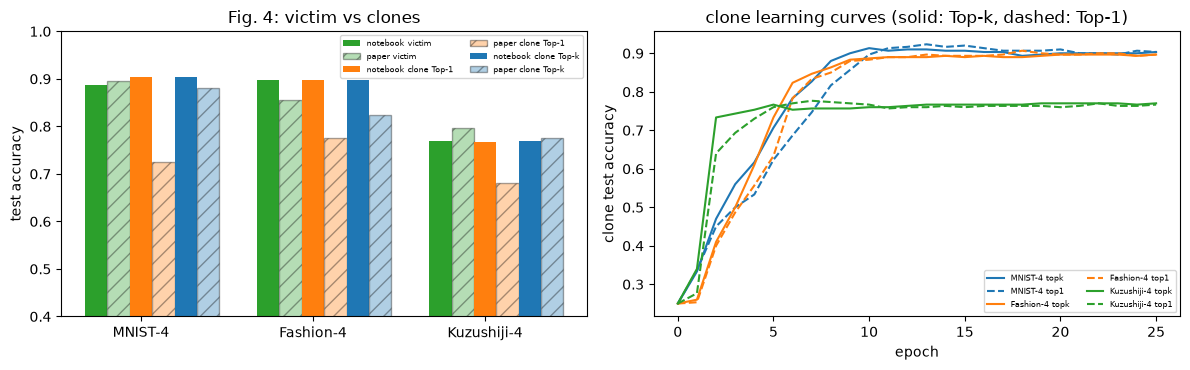


Classical models on the same 8 angles (test accuracy): (a) trained on the 700 true labels, (b) used as the attacker's clone trained on the QNN's Top-1 answers to the same queries
    dataset        model trained_on_true_labels classical_clone_on_QNN_Top1_answers
    MNIST-4      SVC-rbf         0.960 +- 0.000                      0.797 +- 0.000
    MNIST-4 RandomForest         0.950 +- 0.000                      0.827 +- 0.000
    MNIST-4       LogReg         0.947 +- 0.000                      0.887 +- 0.000
  Fashion-4      SVC-rbf         0.947 +- 0.000                      0.883 +- 0.000
  Fashion-4 RandomForest         0.930 +- 0.000                      0.853 +- 0.000
  Fashion-4       LogReg         0.927 +- 0.000                      0.900 +- 0.000
Kuzushiji-4      SVC-rbf         0.900 +- 0.000                      0.740 +- 0.000
Kuzushiji-4 RandomForest         0.883 +- 0.000                      0.690 +- 0.000
Kuzushiji-4       LogReg         0.823 +- 0.000                 

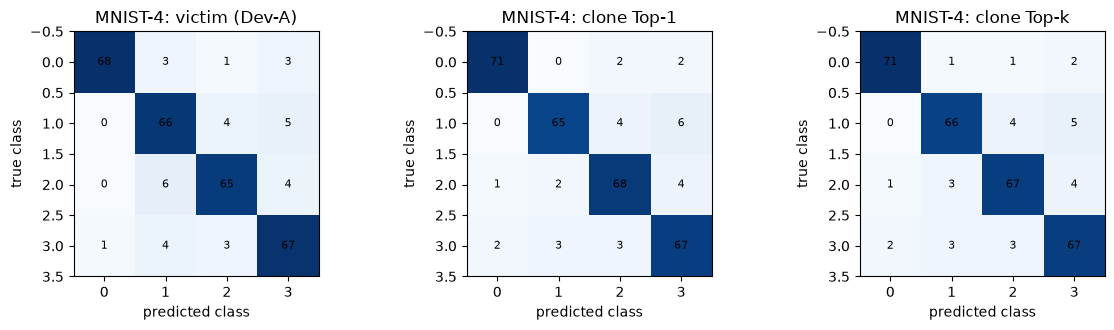

In [13]:
CLAIMS = []         # numeric claims: (source, description, paper value, notebook value, kind)
QCLAIMS = []        # qualitative claims
def claim(source, desc, paper, nb, kind):
    """kind: 'acc' accuracy in points, 'loss' test loss, 'pert' perturbation in percent, 'ratio' clone/victim accuracy ratio."""
    CLAIMS.append(dict(source=source, claim=desc, paper=paper, notebook=nb, kind=kind))
def qclaim(source, desc, holds, detail=""):
    QCLAIMS.append(dict(source=source, claim=desc, verdict="reproduced" if holds else "not reproduced", detail=detail))

PAPER_T1 = {  # Table 1: victim acc, loss | clone Top-1 acc, loss | clone Top-k acc, loss
    "MNIST-4": (0.896, 0.371, 0.726, 0.691, 0.880, 0.547), "Fashion-4": (0.856, 0.475, 0.776, 0.625, 0.823, 0.590), "Kuzushiji-4": (0.796, 0.709, 0.680, 0.782, 0.776, 0.749)}

t0 = time.time(); T1 = {}
for tname in VICTIM_TASKS:
    for sd in SEEDS:
        dom = build_domain(sd); tk = dom[tname]; v, vh = get_victim(tname, sd)
        Xq = query_set(dom, tname, "mixed", N_QUERY, sd); orc = make_oracle(tname, sd, "none")
        r1, rk = steal(orc, Xq, "top1", tname, sd), steal(orc, Xq, "topk", tname, sd)
        lg = v.logits(Enc(tk["fte"], 4, DEV_A), dev=DEV_A)
        T1[(tname, sd)] = dict(victim_acc=vh["test_acc"][-1], victim_loss=vh["test_loss"][-1], top1=r1, topk=rk, victim_ideal=victim_test_acc(v, tk, IDEAL),
                               cls_victim=classical_victim(tk, sd), cls_clone=classical_clone(Xq, r1["P"], tk, sd), victim_pred=lg.argmax(1))
rows = []
for tname in VICTIM_TASKS:
    g = [T1[(tname, sd)] for sd in SEEDS]
    rows.append(dict(dataset=tname, victim_acc=pm([x["victim_acc"] for x in g]), victim_loss=pm([x["victim_loss"] for x in g]),
                     top1_acc=pm([x["top1"]["acc"] for x in g]), top1_loss=pm([x["top1"]["loss"] for x in g]),
                     topk_acc=pm([x["topk"]["acc"] for x in g]), topk_loss=pm([x["topk"]["loss"] for x in g]),
                     top1_ratio=np.mean([x["top1"]["acc"] / x["victim_acc"] for x in g]), topk_ratio=np.mean([x["topk"]["acc"] / x["victim_acc"] for x in g]),
                     top1_fidelity=np.mean([x["top1"]["fidelity"] for x in g]), topk_fidelity=np.mean([x["topk"]["fidelity"] for x in g])))
t1 = pd.DataFrame(rows).set_index("dataset")
print(f"Table 1 analogue: Dev-A victim, Dev-C clone, mixed NPD queries (|D_A| = {N_QUERY}), {EPOCHS} epochs, mean +- std over {len(SEEDS)} repetition(s)   [{time.time()-t0:.0f} s]")
print(t1.round(3).to_string())
pt = pd.DataFrame({k: dict(victim_acc=v[0], victim_loss=v[1], top1_acc=v[2], top1_loss=v[3], topk_acc=v[4], topk_loss=v[5], top1_ratio=v[2] / v[0], topk_ratio=v[4] / v[0]) for k, v in PAPER_T1.items()}).T
print("\nPaper, Table 1 (ratios computed from it):"); print(pt.round(3).to_string())

for tname in VICTIM_TASKS:
    g = [T1[(tname, sd)] for sd in SEEDS]; p = PAPER_T1[tname]
    for i, (lab, key) in enumerate([("victim", None), ("clone Top-1", "top1"), ("clone Top-k", "topk")]):
        acc = np.mean([x["victim_acc"] if key is None else x[key]["acc"] for x in g]); los = np.mean([x["victim_loss"] if key is None else x[key]["loss"] for x in g])
        claim("Table 1", f"{tname} {lab} test accuracy", 100 * p[2 * i], 100 * acc, "acc"); claim("Table 1", f"{tname} {lab} test loss", p[2 * i + 1], los, "loss")
r1_ = np.mean([T1[(t, s)]["top1"]["acc"] / T1[(t, s)]["victim_acc"] for t in VICTIM_TASKS for s in SEEDS]); rk_ = np.mean([T1[(t, s)]["topk"]["acc"] / T1[(t, s)]["victim_acc"] for t in VICTIM_TASKS for s in SEEDS])
claim("Sec. 4.2", "average Top-1 clone accuracy relative to the victim (x)", 0.85, r1_, "ratio"); claim("Sec. 4.2", "average Top-k clone accuracy relative to the victim (x)", 0.98, rk_, "ratio")
best1 = max(T1[(t, s)]["top1"]["acc"] / T1[(t, s)]["victim_acc"] for t in VICTIM_TASKS for s in SEEDS); bestk = max(T1[(t, s)]["topk"]["acc"] / T1[(t, s)]["victim_acc"] for t in VICTIM_TASKS for s in SEEDS)
claim("Abstract", "best Top-1 clone accuracy relative to the victim (x)", 0.90, best1, "ratio"); claim("Abstract", "best Top-k clone accuracy relative to the victim (x)", 0.99, bestk, "ratio")
qclaim("Table 1 / Fig. 4", "Top-k clones are at least as accurate as Top-1 clones on every dataset", all(np.mean([T1[(t, s)]["topk"]["acc"] for s in SEEDS]) >= np.mean([T1[(t, s)]["top1"]["acc"] for s in SEEDS]) for t in VICTIM_TASKS),
       str({t: (round(np.mean([T1[(t, s)]["top1"]["acc"] for s in SEEDS]), 3), round(np.mean([T1[(t, s)]["topk"]["acc"] for s in SEEDS]), 3)) for t in VICTIM_TASKS}))

# ---- Fig. 4: bar chart notebook vs paper ----
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); xs = np.arange(3); w = 0.13
for k, (lab, key, c) in enumerate([("victim", None, "tab:green"), ("clone Top-1", "top1", "tab:orange"), ("clone Top-k", "topk", "tab:blue")]):
    nb = [np.mean([T1[(t, s)]["victim_acc"] if key is None else T1[(t, s)][key]["acc"] for s in SEEDS]) for t in VICTIM_TASKS]
    sd_ = [np.std([T1[(t, s)]["victim_acc"] if key is None else T1[(t, s)][key]["acc"] for s in SEEDS]) for t in VICTIM_TASKS]
    ax[0].bar(xs + (2 * k - 2.5) * w + w / 2, nb, w, yerr=sd_, color=c, label=f"notebook {lab}")
    ax[0].bar(xs + (2 * k - 1.5) * w + w / 2, [PAPER_T1[t][2 * k] for t in VICTIM_TASKS], w, color=c, alpha=0.35, hatch="//", edgecolor="k", label=f"paper {lab}")
ax[0].set_xticks(xs); ax[0].set_xticklabels(VICTIM_TASKS); ax[0].set_ylim(0.4, 1.0); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Fig. 4: victim vs clones"); ax[0].legend(fontsize=6, ncol=2)
for t, c in zip(VICTIM_TASKS, ["tab:blue", "tab:orange", "tab:green"]):
    for key, ls in [("topk", "-"), ("top1", "--")]:
        cv = np.array([T1[(t, s)][key]["curve"] for s in SEEDS]); ax[1].plot(cv.mean(0), ls, color=c, label=f"{t} {key}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("clone test accuracy"); ax[1].set_title("clone learning curves (solid: Top-k, dashed: Top-1)"); ax[1].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

# ---- classical baselines on the identical 8 inputs ----
rows = []
for tname in VICTIM_TASKS:
    for mname in ("SVC-rbf", "RandomForest", "LogReg"):
        rows.append(dict(dataset=tname, model=mname, trained_on_true_labels=pm([T1[(tname, s)]["cls_victim"][mname] for s in SEEDS]),
                         classical_clone_on_QNN_Top1_answers=pm([T1[(tname, s)]["cls_clone"][mname] for s in SEEDS])))
print("\nClassical models on the same 8 angles (test accuracy): (a) trained on the 700 true labels, (b) used as the attacker's clone trained on the QNN's Top-1 answers to the same queries")
print(pd.DataFrame(rows).to_string(index=False))

# ---- confusion matrices for the first dataset and seed ----
tn = VICTIM_TASKS[0]; sd = SEEDS[0]; tk = build_domain(sd)[tn]; x = T1[(tn, sd)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for a, (ttl, pred) in zip(axes, [("victim (Dev-A)", x["victim_pred"]), ("clone Top-1", x["top1"]["pred"]), ("clone Top-k", x["topk"]["pred"])]):
    M = confusion(tk["yte"], pred); a.imshow(M, cmap="Blues"); a.set_title(f"{tn}: {ttl}"); a.set_xlabel("predicted class"); a.set_ylabel("true class")
    for i in range(4):
        for j in range(4): a.text(j, i, M[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

### 3.1 Fig. 5: what makes a better clone?

Four sweeps (Top-1 and Top-k each): (a) the size of the attacker dataset $\lvert D_A\rvert$, (b) the clone's circuit, (c) the clone's number of qubits, (d) mixed NPD queries versus uniformly random features. Everything else is as in Table 1. The victim is always the PQC-1, 4-qubit model of the dataset.

Fig. 5 sweeps done in 178 s for datasets ['MNIST-4'], 1 repetition(s); clone test accuracy, mean over datasets and repetitions

Fig. 5(a) size of the attacker dataset
       Top-1  Top-k  Top-1 fidelity  Top-k fidelity
|D_A|                                              
175    0.767  0.803           0.757           0.797
350    0.900  0.907           0.940           0.957
700    0.903  0.900           0.957           0.970
1400   0.893  0.883           0.977           0.997

Fig. 5(b) clone circuit
               Top-1  Top-k  Top-1 fidelity  Top-k fidelity
clone circuit                                              
PQC-1          0.903  0.900           0.957            0.97
PQC-17         0.480  0.863           0.470            0.88

Fig. 5(c) clone width
              Top-1  Top-k  Top-1 fidelity  Top-k fidelity
clone qubits                                              
2             0.343  0.357           0.330           0.343
4             0.903  0.900           0.957           0.9

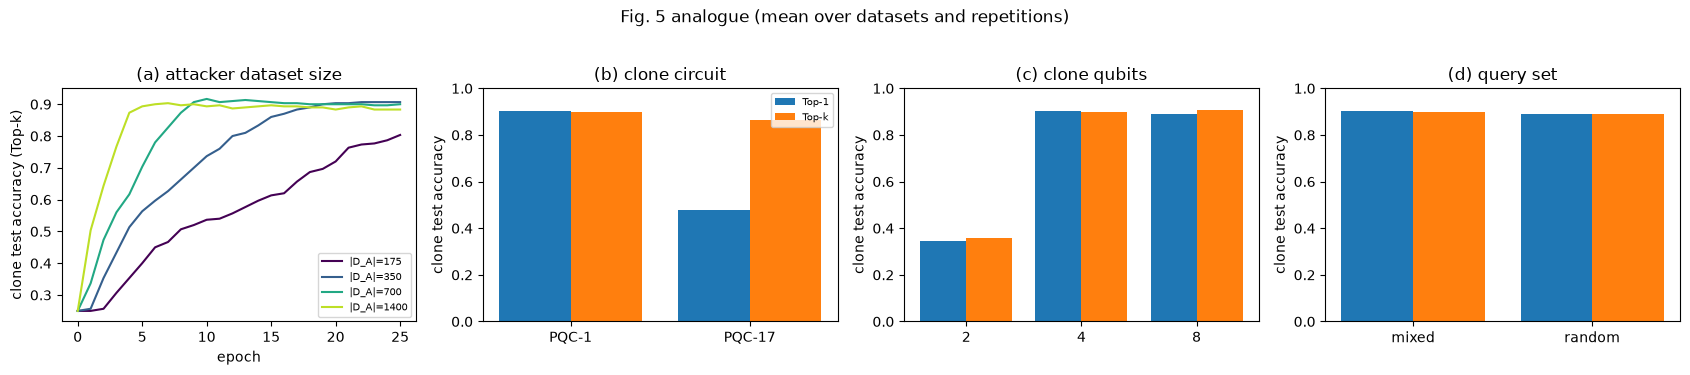

In [14]:
F5 = {}     # (panel, setting, task, seed, mode) -> result dict of steal()
def run_f5(panel, setting, tname, sd, mode, **kw):
    key = (panel, setting, tname, sd, mode)
    if key not in F5:
        dom = build_domain(sd); orc = make_oracle(tname, sd, "none")
        Xq = query_set(dom, tname, kw.pop("kind", "mixed"), kw.pop("n", N_QUERY), sd)
        F5[key] = steal(orc, Xq, mode, tname, sd, **kw)
    return F5[key]
def f5_mean(panel, setting, mode, key="acc"):
    return np.mean([run_f5(panel, setting, t, s, mode)[key] for t in FIG5_TASKS for s in SEEDS])

t0 = time.time()
# (a) size of the attacker dataset
for n in DA_SIZES:
    for t in FIG5_TASKS:
        for s in SEEDS:
            for mode in ("top1", "topk"): run_f5("a", n, t, s, mode, n=n)
# (b) clone circuit (the victim stays PQC-1)
for pqc in ARCH_CLONES:
    for t in FIG5_TASKS:
        for s in SEEDS:
            for mode in ("top1", "topk"): run_f5("b", pqc, t, s, mode, clone_pqc=pqc)
# (c) clone width
for nq in WIDTHS:
    for t in FIG5_TASKS:
        for s in SEEDS:
            for mode in ("top1", "topk"): run_f5("c", nq, t, s, mode, clone_n=nq)
# (d) mixed NPD queries versus random features
for kind in ("mixed", "random"):
    for t in FIG5_TASKS:
        for s in SEEDS:
            for mode in ("top1", "topk"): run_f5("d", kind, t, s, mode, kind=kind)
print(f"Fig. 5 sweeps done in {time.time()-t0:.0f} s for datasets {FIG5_TASKS}, {len(SEEDS)} repetition(s); clone test accuracy, mean over datasets and repetitions")

def f5_table(panel, settings, label):
    rows = []
    for st in settings:
        rows.append({label: st, "Top-1": f5_mean(panel, st, "top1"), "Top-k": f5_mean(panel, st, "topk"),
                     "Top-1 fidelity": f5_mean(panel, st, "top1", "fidelity"), "Top-k fidelity": f5_mean(panel, st, "topk", "fidelity")})
    return pd.DataFrame(rows).set_index(label)
ta, tb, tc, td = f5_table("a", DA_SIZES, "|D_A|"), f5_table("b", ARCH_CLONES, "clone circuit"), f5_table("c", WIDTHS, "clone qubits"), f5_table("d", ["mixed", "random"], "query set")
for name, tab in [("(a) size of the attacker dataset", ta), ("(b) clone circuit", tb), ("(c) clone width", tc), ("(d) mixed vs random queries", td)]:
    print(f"\nFig. 5{name}"); print(tab.round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for n, c in zip(DA_SIZES, plt.cm.viridis(np.linspace(0, 0.9, len(DA_SIZES)))):
    cv = np.array([run_f5("a", n, t, s, "topk")["curve"] for t in FIG5_TASKS for s in SEEDS]); axes[0].plot(cv.mean(0), color=c, label=f"|D_A|={n}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("clone test accuracy (Top-k)"); axes[0].set_title("(a) attacker dataset size"); axes[0].legend(fontsize=7)
for ax, tab, ttl in [(axes[1], tb, "(b) clone circuit"), (axes[2], tc, "(c) clone qubits"), (axes[3], td, "(d) query set")]:
    xs = np.arange(len(tab)); ax.bar(xs - 0.2, tab["Top-1"], 0.4, label="Top-1"); ax.bar(xs + 0.2, tab["Top-k"], 0.4, label="Top-k")
    ax.set_xticks(xs); ax.set_xticklabels([str(i) for i in tab.index]); ax.set_ylim(0, 1); ax.set_title(ttl); ax.set_ylabel("clone test accuracy")
axes[1].legend(fontsize=7); plt.suptitle("Fig. 5 analogue (mean over datasets and repetitions)", y=1.03); plt.tight_layout(); plt.show()

# ---- qualitative claims of Sec. 4.2 (a gap counts only if it is at least MARGIN = 2 accuracy points; smaller differences are within run-to-run noise) ----
MARGIN = 0.02
big = [n for n in DA_SIZES if n >= 350]; spread = ta.loc[big, "Top-k"].max() - ta.loc[big, "Top-k"].min()
qclaim("Fig. 5a", "Final clone accuracy is similar for different |D_A| (Top-k spread of at most 5 points over |D_A| = 350 ... 1400)", spread <= 0.05, f"Top-k accuracy by |D_A|: {ta['Top-k'].round(3).to_dict()} (spread over 350+ = {100*spread:.1f} points)")
qclaim("Fig. 5a", "Larger sets learn faster (accuracy after epoch 5 is higher for |D_A| = 1400 than for 175, Top-k)",
       bool(np.mean([run_f5("a", max(DA_SIZES), t, s, "topk")["curve"][5] for t in FIG5_TASKS for s in SEEDS]) > np.mean([run_f5("a", min(DA_SIZES), t, s, "topk")["curve"][5] for t in FIG5_TASKS for s in SEEDS])),
       "accuracy after 5 epochs: " + str({n: round(float(np.mean([run_f5("a", n, t, s, "topk")["curve"][5] for t in FIG5_TASKS for s in SEEDS])), 3) for n in DA_SIZES}))
qclaim("Fig. 5a", "A smaller |D_A| than the victim's training set is enough (|D_A| = 350 within 5 points of |D_A| = 700, Top-k)", abs(ta.loc[350, "Top-k"] - ta.loc[700, "Top-k"]) <= 0.05, f"{ta.loc[350,'Top-k']:.3f} vs {ta.loc[700,'Top-k']:.3f}")
qclaim("Fig. 5b", "The simplest clone circuit (PQC-1) is at least as good as the more complex ones (Top-k and Top-1)", bool((tb.loc["PQC-1", ["Top-1", "Top-k"]] >= tb[["Top-1", "Top-k"]].max(axis=0) - 0.005).all()), str(tb[["Top-1", "Top-k"]].round(3).to_dict("index")))
qclaim("Fig. 5c", "An 8-qubit clone beats the 4-qubit clone by at least 2 points (Top-k)", bool(tc.loc[8, "Top-k"] >= tc.loc[4, "Top-k"] + MARGIN), str(tc["Top-k"].round(3).to_dict()))
qclaim("Fig. 5c", "The 2-qubit clone lags the 4-qubit clone by at least 2 points (Top-k)", bool(tc.loc[2, "Top-k"] <= tc.loc[4, "Top-k"] - MARGIN), str(tc["Top-k"].round(3).to_dict()))
qclaim("Fig. 5d", "Random query features underperform the mixed NPD query set by at least 2 points (Top-1 and Top-k)", bool(td.loc["random", "Top-1"] <= td.loc["mixed", "Top-1"] - MARGIN and td.loc["random", "Top-k"] <= td.loc["mixed", "Top-k"] - MARGIN), str(td[["Top-1", "Top-k"]].round(3).to_dict("index")))

## 4. The defences HVIP and HAVIP: Table 2 and Fig. 6

**HVIP.** The victim QNN is trained for 20 epochs on Dev-A and fine-tuned for 5 epochs on Dev-B; each incoming query is executed on Dev-A or Dev-B with probability 50 %.
**HAVIP.** Two different QNNs (the PQC-1 model on Dev-A and a PQC-19 model trained on Dev-B) are hosted; each query is answered by one of them with probability 50 %.
**Perturbation (Table 2).** The same 700 mixed queries are sent to the defended service and to the undefended reference (the defence's first model, always on Dev-A). Top-1: share of queries whose label differs; Top-k: mean total variation distance between the two probability vectors.
We show the perturbation with exact expectation values (the effect of the hardware alone) and with 1000-shot noise (what an attacker would actually see, including the shot noise that both services have).
**Effect on the attack (Fig. 6).** Clones are trained on the defended answers (on Dev-C, as before) and scored on the test set; the undefended clone is the reference.

Defence experiments done in 301 s
Table 2 analogue: perturbation added by the defences relative to the undefended service (exact expectation values; the (1000 shots) columns include finite-shot noise on both sides)
             HVIP Top-1 mismatch %  HVIP Top-k TVD %  HVIP Top-1 (1000 shots) %  HVIP Top-k (1000 shots) %  HAVIP Top-1 mismatch %  HAVIP Top-k TVD %  HAVIP Top-1 (1000 shots) %  HAVIP Top-k (1000 shots) %
dataset                                                                                                                                                                                                      
MNIST-4                       2.00              1.79                       2.29                       2.28                    6.00               4.66                        6.71                        5.25
Fashion-4                     1.43              1.69                       3.43                       2.42                    6.29               5.77                  

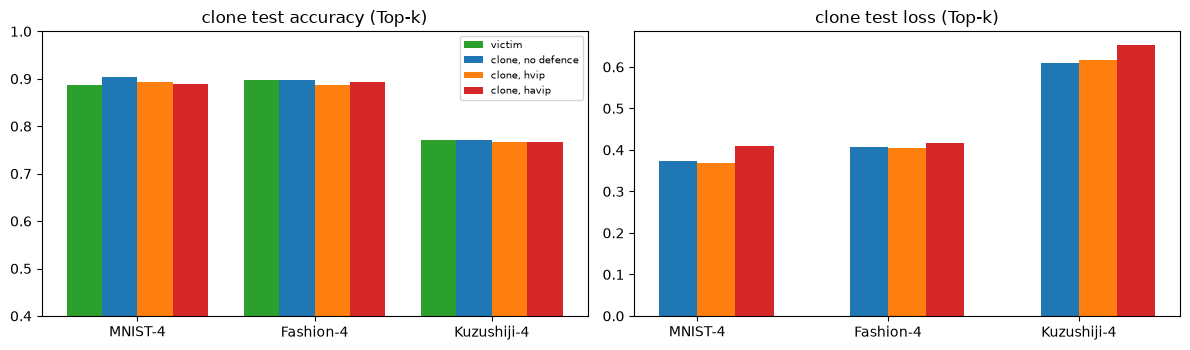

In [15]:
PAPER_T2 = {  # Table 2: perturbation added by HVIP / HAVIP in percent: (HVIP Top-1, HVIP Top-k, HAVIP Top-1, HAVIP Top-k)
    "MNIST-4": (10.29, 6.1, 11.2, 8.3), "Fashion-4": (8.14, 5.6, 15.71, 10.2), "Kuzushiji-4": (8.43, 4.7, 14.29, 6.4)}
DEFENCES = ["none", "hvip", "havip"]
DEF = {}      # (task, seed, defence) -> dict

t0 = time.time()
for tname in DEF_TASKS:
    for sd in SEEDS:
        dom = build_domain(sd); tk = dom[tname]; Xq = query_set(dom, tname, "mixed", N_QUERY, sd)
        for dfn in DEFENCES:
            orc = make_oracle(tname, sd, dfn); out = {}
            if dfn != "none":
                base = make_baseline(tname, sd, dfn)
                for tag, exact in (("exact", True), ("shots", False)):
                    Pd, Pb = orc.probs(Xq, exact=exact), base.probs(Xq, exact=exact)
                    out[f"mismatch_{tag}"] = 100 * float((Pd.argmax(1) != Pb.argmax(1)).mean()); out[f"tvd_{tag}"] = 100 * float(0.5 * np.abs(Pd - Pb).sum(1).mean())
            for mode in ("top1", "topk"): out[mode] = steal(orc, Xq, mode, tname, sd)
            v = get_victim(tname, sd, "hvip" if dfn == "hvip" else "base")[0]
            out["victim_acc_A"], out["victim_acc_B"] = victim_test_acc(v, tk, DEV_A), victim_test_acc(v, tk, DEV_B)
            DEF[(tname, sd, dfn)] = out
print(f"Defence experiments done in {time.time()-t0:.0f} s")

# ---- Table 2: perturbation ----
rows = []
for tname in DEF_TASKS:
    row = dict(dataset=tname)
    for dfn in ("hvip", "havip"):
        g = [DEF[(tname, s, dfn)] for s in SEEDS]
        row[f"{dfn.upper()} Top-1 mismatch %"] = np.mean([x["mismatch_exact"] for x in g]); row[f"{dfn.upper()} Top-k TVD %"] = np.mean([x["tvd_exact"] for x in g])
        row[f"{dfn.upper()} Top-1 (1000 shots) %"] = np.mean([x["mismatch_shots"] for x in g]); row[f"{dfn.upper()} Top-k (1000 shots) %"] = np.mean([x["tvd_shots"] for x in g])
    rows.append(row)
t2 = pd.DataFrame(rows).set_index("dataset")
print("Table 2 analogue: perturbation added by the defences relative to the undefended service (exact expectation values; the (1000 shots) columns include finite-shot noise on both sides)")
print(t2.round(2).to_string())
print("\nPaper, Table 2 (%):"); print(pd.DataFrame(PAPER_T2, index=["HVIP Top-1", "HVIP Top-k", "HAVIP Top-1", "HAVIP Top-k"]).T.to_string())
for tname in DEF_TASKS:
    for j, (dfn, mode, key) in enumerate([("hvip", "Top-1", "mismatch_exact"), ("hvip", "Top-k", "tvd_exact"), ("havip", "Top-1", "mismatch_exact"), ("havip", "Top-k", "tvd_exact")]):
        claim("Table 2", f"{tname} {dfn.upper()} {mode} perturbation (%)", PAPER_T2[tname][j], np.mean([DEF[(tname, s, dfn)][key] for s in SEEDS]), "pert")
m = lambda dfn, key: np.mean([DEF[(t, s, dfn)][key] for t in DEF_TASKS for s in SEEDS])
qclaim("Table 2", "HAVIP perturbs the outputs more than HVIP (Top-1 and Top-k)", m("havip", "mismatch_exact") > m("hvip", "mismatch_exact") and m("havip", "tvd_exact") > m("hvip", "tvd_exact"),
       f"Top-1 {m('hvip','mismatch_exact'):.1f} vs {m('havip','mismatch_exact'):.1f} %, Top-k {m('hvip','tvd_exact'):.1f} vs {m('havip','tvd_exact'):.1f} %")
qclaim("Sec. 4.3", "The defences obfuscate the outputs by up to about 16 % (largest Top-1 mismatch between 8 % and 20 %)", 8 <= max(DEF[(t, s, d)]["mismatch_exact"] for t in DEF_TASKS for s in SEEDS for d in ("hvip", "havip")) <= 20,
       "largest observed Top-1 mismatch %.1f %%" % max(DEF[(t, s, d)]["mismatch_exact"] for t in DEF_TASKS for s in SEEDS for d in ("hvip", "havip")))

# ---- Fig. 6: clone accuracy and loss with and without defence (Top-k as in the paper; Top-1 in the table) ----
rows = []
for tname in DEF_TASKS:
    for mode in ("topk", "top1"):
        row = dict(dataset=tname, answers=mode, victim=np.mean([DEF[(tname, s, "none")]["victim_acc_A"] for s in SEEDS]))
        for dfn in DEFENCES: row[f"clone acc, {dfn}"] = np.mean([DEF[(tname, s, dfn)][mode]["acc"] for s in SEEDS]); row[f"clone loss, {dfn}"] = np.mean([DEF[(tname, s, dfn)][mode]["loss"] for s in SEEDS])
        row["drop HVIP"] = row["clone acc, none"] - row["clone acc, hvip"]; row["drop HAVIP"] = row["clone acc, none"] - row["clone acc, havip"]; rows.append(row)
t6 = pd.DataFrame(rows).set_index(["dataset", "answers"])
print("\nFig. 6 analogue: clone test accuracy / loss without defence, with HVIP and with HAVIP"); print(t6.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6)); xs = np.arange(len(DEF_TASKS)); w = 0.2
for key, ax, ttl in [("acc", axes[0], "clone test accuracy (Top-k)"), ("loss", axes[1], "clone test loss (Top-k)")]:
    if key == "acc": ax.bar(xs - 1.5 * w, [t6.loc[(t, "topk"), "victim"] for t in DEF_TASKS], w, color="tab:green", label="victim")
    for k, (dfn, c) in enumerate([("none", "tab:blue"), ("hvip", "tab:orange"), ("havip", "tab:red")]):
        vals = [t6.loc[(t, "topk"), f"clone {key}, {dfn}"] for t in DEF_TASKS]; ax.bar(xs + (k - 0.5) * w, vals, w, color=c, label=f"clone, {dfn if dfn != 'none' else 'no defence'}")
    ax.set_xticks(xs); ax.set_xticklabels(DEF_TASKS); ax.set_title(ttl)
axes[0].set_ylim(0.4, 1); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
for tname in DEF_TASKS:
    qclaim("Fig. 6", f"{tname}: clone accuracy under HVIP and HAVIP stays within 5 points of the undefended clone (Top-k)",
           bool(max(t6.loc[(tname, "topk"), "drop HVIP"], t6.loc[(tname, "topk"), "drop HAVIP"]) * 100 <= 5), f"drops: HVIP {100*t6.loc[(tname,'topk'),'drop HVIP']:.1f}, HAVIP {100*t6.loc[(tname,'topk'),'drop HAVIP']:.1f} points")
claim("Fig. 6", "Fashion-4 clone accuracy drop under HAVIP (points, Top-k)", 13.0, 100 * t6.loc[("Fashion-4", "topk"), "drop HAVIP"], "acc")
qclaim("Sec. 4.3", "The defences do not stop the attack: average Top-k clone accuracy under either defence stays above 90 % of the undefended clone's", bool(min(t6.xs("topk", level=1)["clone acc, hvip"].mean(), t6.xs("topk", level=1)["clone acc, havip"].mean()) >= 0.9 * t6.xs("topk", level=1)["clone acc, none"].mean()),
       f"mean Top-k clone accuracy: none {t6.xs('topk', level=1)['clone acc, none'].mean():.3f}, HVIP {t6.xs('topk', level=1)['clone acc, hvip'].mean():.3f}, HAVIP {t6.xs('topk', level=1)['clone acc, havip'].mean():.3f}")

## 5. Why do the defences fail? A control experiment

The paper's explanation is that models trained under noise are "naturally resistant" to perturbations. Two checks on that idea, which the paper does not run:
1. **Noisy versus noise-free clone.** If the explanation is right, a clone trained on a noise-free simulator should lose *more* accuracy to HAVIP than a clone trained on a noisy device.
2. **Dose-response.** Replace a fraction of the Top-1 answers by a random wrong class (a much cruder obfuscation than the hardware variation) and see how much corruption a QNN clone, trained noisy or noise-free, and a classical SVC clone absorb.

Control 1 (1 dataset(s), 1 repetition(s); one point = 0.01 accuracy):
              clone answers  no_defence  with_HAVIP  accuracy_loss_points
noisy clone (Dev-C)    top1       0.903       0.903                 0.000
noisy clone (Dev-C)    topk       0.903       0.893                 1.000
   noise-free clone    top1       0.900       0.900                 0.000
   noise-free clone    topk       0.900       0.893                 0.667



Control 2: Top-1 clone test accuracy (MNIST-4) when a fraction of the victim's answers is replaced by a random wrong class
               noisy QNN clone  noise-free QNN clone  classical SVC clone
flip_fraction                                                            
0.0                      0.900                 0.887                0.797
0.1                      0.903                 0.903                0.730
0.2                      0.887                 0.893                0.760
0.3                      0.873                 0.880                0.790
0.4                      0.870                 0.823                0.683


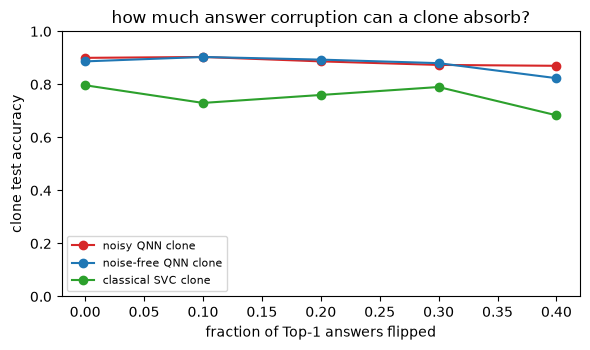

[65 s]


In [16]:
CTRL = {}
t0 = time.time()
# (1) Do the defences hurt a clone that was trained WITHOUT hardware noise more than one trained on noisy hardware (Dev-C)?
for tname in CTRL_TASKS:
    for sd in SEEDS:
        dom = build_domain(sd); Xq = query_set(dom, tname, "mixed", N_QUERY, sd)
        for dname, cdev in (("noisy clone (Dev-C)", DEV_C), ("noise-free clone", IDEAL)):
            for dfn in ("none", "havip"):
                orc = make_oracle(tname, sd, dfn)
                for mode in ("top1", "topk"): CTRL[("def", tname, sd, dname, dfn, mode)] = steal(orc, Xq, mode, tname, sd, clone_dev=cdev)["acc"]
rows = []
for dname in ("noisy clone (Dev-C)", "noise-free clone"):
    for mode in ("top1", "topk"):
        a0 = np.mean([CTRL[("def", t, s, dname, "none", mode)] for t in CTRL_TASKS for s in SEEDS]); a1 = np.mean([CTRL[("def", t, s, dname, "havip", mode)] for t in CTRL_TASKS for s in SEEDS])
        rows.append(dict(clone=dname, answers=mode, no_defence=a0, with_HAVIP=a1, accuracy_loss_points=100 * (a0 - a1)))
c1 = pd.DataFrame(rows)
print(f"Control 1 ({len(CTRL_TASKS)} dataset(s), {len(SEEDS)} repetition(s); one point = 0.01 accuracy):"); print(c1.round(3).to_string(index=False))

# (2) Dose-response: flip a fraction of the Top-1 answers to a random wrong class and watch the clone (QNN trained noisy / noise-free, and a classical SVC)
FLIPS = [0.0, 0.1, 0.2, 0.3, 0.4]
for tname in CTRL_TASKS[:1]:
    for sd in SEEDS:
        dom = build_domain(sd); tk = dom[tname]; Xq = query_set(dom, tname, "mixed", N_QUERY, sd); orc = make_oracle(tname, sd, "none"); P = orc.probs(Xq)
        for f in FLIPS:
            for dname, cdev in (("noisy QNN clone", DEV_C), ("noise-free QNN clone", IDEAL)): CTRL[("flip", tname, sd, dname, f)] = steal(orc, Xq, "top1", tname, sd, clone_dev=cdev, flip=f)["acc"]
            lab = P.argmax(1).copy(); r_ = np.random.default_rng(sd + 31); hit = r_.random(len(lab)) < f; lab[hit] = (lab[hit] + r_.integers(1, 4, hit.sum())) % 4
            CTRL[("flip", tname, sd, "classical SVC clone", f)] = float(SVC(random_state=sd).fit(Xq, lab).score(tk["fte"], tk["yte"]))
rows = [dict(flip_fraction=f, **{d: np.mean([CTRL[("flip", t, s, d, f)] for t in CTRL_TASKS[:1] for s in SEEDS]) for d in ("noisy QNN clone", "noise-free QNN clone", "classical SVC clone")}) for f in FLIPS]
c2 = pd.DataFrame(rows).set_index("flip_fraction")
print(f"\nControl 2: Top-1 clone test accuracy ({CTRL_TASKS[0]}) when a fraction of the victim's answers is replaced by a random wrong class"); print(c2.round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 3.6))
for d, c in [("noisy QNN clone", "tab:red"), ("noise-free QNN clone", "tab:blue"), ("classical SVC clone", "tab:green")]: ax.plot(FLIPS, c2[d], "o-", color=c, label=d)
ax.set_xlabel("fraction of Top-1 answers flipped"); ax.set_ylabel("clone test accuracy"); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title("how much answer corruption can a clone absorb?")
plt.tight_layout(); plt.show()
print(f"[{time.time()-t0:.0f} s]")
loss_noisy = c1[c1.clone == "noisy clone (Dev-C)"].accuracy_loss_points.mean(); loss_free = c1[c1.clone == "noise-free clone"].accuracy_loss_points.mean()
qclaim("Sec. 4.3 / Conclusion", "Noisy-trained clones lose less accuracy to the defences than noise-free clones (the paper's explanation for the failure of HVIP/HAVIP)", bool(loss_noisy <= loss_free - 2.0),
       f"mean accuracy loss under HAVIP: noisy clone {loss_noisy:.1f} points, noise-free clone {loss_free:.1f} points (differences below ~2 points are within run-to-run noise)")

## 6. The paper's numbers next to this notebook's

Verdict rules (repository conventions): a number is **reproduced** if it is within 2 accuracy points of the paper's value (perturbation percentages: 2 points; accuracy ratios: 0.02; test loss: 0.10, because the paper does not define how its loss was computed);
otherwise **not reached** (lower than the paper's value) or **exceeded** (higher). For test losses the verdict only gives the sign (**above paper** / **below paper**). **Cannot be checked** is used for claims whose ingredients the paper does not publish.
Qualitative claims (orderings and trends), on which the paper's argument rests, are judged separately.

In [17]:
TOL = {"acc": 2.0, "loss": 0.10, "pert": 2.0, "ratio": 0.02}
def verdict(paper, nb, kind):
    d = nb - paper
    if abs(d) <= TOL[kind]: return "reproduced"
    if kind in ("acc", "ratio", "pert"): return "exceeded" if d > 0 else "not reached"          # more accuracy / clone quality / obfuscation than the paper = exceeded
    return "above paper" if d > 0 else "below paper"                                              # test loss: neither direction is a success, so just the sign

C = pd.DataFrame(CLAIMS); C["gap"] = C.notebook - C.paper; C["verdict"] = [verdict(r.paper, r.notebook, r.kind) for r in C.itertuples()]
pd.set_option("display.max_rows", 400)
summary = C.groupby(["source", "verdict"]).size().unstack(fill_value=0); summary["total"] = summary.sum(axis=1)
print("Numeric claims (tolerances: accuracy and perturbation 2 points, loss 0.10, accuracy ratio 0.02):"); print(summary.to_string())
print(f"\nOverall: {int((C.verdict=='reproduced').sum())} of {len(C)} numeric values reproduced; verdict counts {C.verdict.value_counts().to_dict()}")
show = C[["source", "claim", "paper", "notebook", "gap", "verdict"]].copy(); show["paper"] = show.paper.round(3); show["notebook"] = show.notebook.round(3); show["gap"] = show.gap.round(3)
print(); print(show.to_string(index=False))
Q = pd.DataFrame(QCLAIMS); print("\nQualitative claims:"); print(Q[["source", "claim", "verdict"]].to_string(index=False))
print("\nDetails:"); [print(f" - [{r.source}] {r.claim}: {r.detail}") for r in Q.itertuples()]
cnc = pd.DataFrame([
    dict(source="Sec. 4.1", claim="Exact noise parameters, coupling maps and basis gates of the paper's two simulated devices", verdict="cannot be checked"),
    dict(source="Sec. 4.1", claim="Convolutional autoencoder architecture and latent space (replaced by PCA to 8 components)", verdict="cannot be checked"),
    dict(source="Abstract / Conclusion", claim="'0.95x' average clone accuracy (the text also gives 0.85x/0.98x; the averaging is not defined)", verdict="cannot be checked"),
    dict(source="Sec. 4.2", claim="Run-to-run variance of the paper's numbers (single runs, no error bars)", verdict="cannot be checked")])
print(); print(cnc.to_string(index=False))
print(f"\nTotal notebook runtime: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE={FAST_MODE})")

Numeric claims (tolerances: accuracy and perturbation 2 points, loss 0.10, accuracy ratio 0.02):
verdict   below paper  exceeded  not reached  reproduced  total
source                                                         
Abstract            0         2            0           0      2
Fig. 6              0         0            1           0      1
Sec. 4.2            0         2            0           0      2
Table 1             8         6            1           3     18
Table 2             0         1           11           0     12



Overall: 3 of 35 numeric values reproduced; verdict counts {'not reached': 13, 'exceeded': 11, 'below paper': 8, 'reproduced': 3}

  source                                                     claim  paper  notebook     gap     verdict
 Table 1                              MNIST-4 victim test accuracy 89.600    88.667  -0.933  reproduced
 Table 1                                  MNIST-4 victim test loss  0.371     0.334  -0.037  reproduced
 Table 1                         MNIST-4 clone Top-1 test accuracy 72.600    90.333  17.733    exceeded
 Table 1                             MNIST-4 clone Top-1 test loss  0.691     0.344  -0.347 below paper
 Table 1                         MNIST-4 clone Top-k test accuracy 88.000    90.333   2.333    exceeded
 Table 1                             MNIST-4 clone Top-k test loss  0.547     0.373  -0.174 below paper
 Table 1                            Fashion-4 victim test accuracy 85.600    89.667   4.067    exceeded
 Table 1                            


Qualitative claims:
               source                                                                                                                                  claim        verdict
     Table 1 / Fig. 4                                                                 Top-k clones are at least as accurate as Top-1 clones on every dataset     reproduced
              Fig. 5a                       Final clone accuracy is similar for different |D_A| (Top-k spread of at most 5 points over |D_A| = 350 ... 1400)     reproduced
              Fig. 5a                                       Larger sets learn faster (accuracy after epoch 5 is higher for |D_A| = 1400 than for 175, Top-k)     reproduced
              Fig. 5a                           A smaller |D_A| than the victim's training set is enough (|D_A| = 350 within 5 points of |D_A| = 700, Top-k)     reproduced
              Fig. 5b                                      The simplest clone circuit (PQC-1) is at least as good as th

## 7. Reading the paper critically

The committed outputs come from one run of the notebook with `FAST_MODE = True` (one repetition, MNIST-4 only for the Fig. 5 sweeps, no PQC-6 clone). Every number below is therefore a **single run** on 300 test images (one image = 0.33 points, standard error near 90 % about 1.7 points); differences of 1 to 3 points are inside the noise.

* **What the evidence supports.** Model stealing against hybrid QNNs works in this pipeline: with 700 unlabeled queries from other datasets, a clone trained on the answers reaches the victim's accuracy (clone 0.90 / 0.90 / 0.77 against victim 0.89 / 0.90 / 0.77 on MNIST-4 / Fashion-4 / Kuzushiji-4) and agrees with the victim's prediction on 95 to 99 % of the test images, whether the cloud returns only the Top-1 label or the whole probability vector. A few qualitative statements of the paper hold: Top-k is never worse than Top-1,
  a dataset smaller than the victim's training set suffices (350 queries are as good as 700; 175 are not: 0.80), larger sets learn faster, the simple PQC-1 clone is better than PQC-17, and a 2-qubit clone (only two outputs for four classes) cannot work.
* **The attack is stronger here than in the paper, and the Top-1 / Top-k gap is not reproduced.** The paper's clones reach 0.85x (Top-1) and 0.98x (Top-k) of the victim; here both are about 1.0x, and the Top-1 and Top-k clones are indistinguishable. Likely reasons: our victim and clone are the same simple circuit family (PQC-1: a smooth function of eight angles that 700 answers pin down), the devices
  are mildly noisy, and our features (PCA) differ from the paper's autoencoder. The paper's low Top-1 numbers (0.68 to 0.78) may also reflect a harder optimisation (noisier gradients, 1000 shots in training, a different clone circuit). We cannot tell which, because the paper gives neither noise parameters nor circuit details.
* **Two Fig. 5 trends are not reproduced.** An 8-qubit clone is not better than a 4-qubit one (0.907 against 0.900, a tie), and random query features work as well as the mixed non-problem-domain queries (0.89 against 0.90; the paper finds random queries "considerably" worse). The scatter plot in the data section shows why this is plausible here: the victim is a smooth function of the angles and uniformly random angles cover its input square as well as the images of other datasets do.
  The PQC-17 clone that trains on Top-1 labels collapses to 0.48 in this single run while its Top-k twin reaches 0.86: SPSA with a fixed step is a fragile optimiser, and one seed is not enough to rank circuits; the full-budget setting (3 repetitions, PQC-6 clone) was not run (see the runtime note).
* **The defences perturb the outputs less than reported and do not stop the attack.** With the three devices fixed in advance, HVIP changes 1.4 to 3.3 % of the Top-1 labels (paper: 8.1 to 10.3 %) and HAVIP 6.0 to 11.1 % (paper: 11.2 to 15.7 %); the total variation distances are 1.7 to 2.7 % and 4.7 to 10.8 % (paper: 4.7 to 6.1 % and 6.4 to 10.2 %). HAVIP perturbs more than HVIP, as in the paper, because swapping the *circuit* changes outputs more than swapping the *device*;
  with a half-and-half router HVIP can change at most half of the labels anyway. The size of the perturbation is set entirely by the unpublished device parameters, so the numerical gap says more about our parameter choice than about the paper. The conclusion that clones trained on defended answers lose almost nothing (1.3 points or less with Top-k answers, 3 points at worst with Top-1) agrees with the paper, but we do not see its 13-point drop on Fashion-4 under HAVIP.
* **The paper's explanation is not supported by the control experiment.** The paper attributes the failure of the defences to QNNs being "naturally resilient" when trained on noisy hardware. A noise-free clone loses just as little to HAVIP as a clone trained on a noisy device (0.3 against 0.5 points), and a clone absorbs flipping of 30 to 40 % of the Top-1 answers to random wrong classes (noisy clone 0.87 at both 30 % and 40 % against 0.90 unperturbed; noise-free clone 0.88 and 0.82) without breaking.
  The simplest reading is that any learner fitted to 700 answers of a smooth, low-capacity function averages out a few percent of perturbation, with or without hardware noise; the control does not isolate noise as the cause. A classical SVC clone is, in this single run, *less* robust to flips than the QNN clone (0.68 to 0.79), but also starts lower, so no conclusion about quantum robustness follows.
* **The attack is not specific to quantum models.** An SVC, a random forest or a logistic regression trained on the QNN's Top-1 answers to the same queries reaches 0.69 to 0.90, and classical models trained on the true labels of the same eight numbers reach 0.82 to 0.96, i.e. as good as or better than the 4-qubit QNN victim (0.77 to 0.90). The paper does not compare with a classical clone or a classical victim.
* **Details that matter and are not given.** The encoding order changes validation accuracy from 40 % to 85 % (Section 2.1), so "angle encoding with $R_Z$ gates" cannot be reproduced without the paper's exact order; the circuits are only named; the noise parameters, device qubits and coupling maps are missing; the loss in Table 1 is undefined; the paper has no error bars and no repeated runs, while the effects it interprets (Fig. 5b to 5d, the 13-point drop) are of the size of the run-to-run noise.
* **What would make the paper stronger.** Released code and noise parameters, repeated runs with error bars, a classical clone and a classical victim as baselines, stronger and cheaper defences (rounding or randomised response on the output; the dose-response in Section 5 shows how much corruption is needed), and a test of the "noise resilience" explanation with noise-free clones, as done here.
* **Reproduction verdict.** The qualitative core (stealing works, Top-k at least as good as Top-1, small query sets suffice, simple circuits and four qubits are enough, defences fail) is reproduced; of the 35 numeric values the table in Section 6 lists, only the MNIST-4 victim accuracy and loss and the Kuzushiji-4 Top-k clone accuracy fall within tolerance, because our clones are better and our defences weaker than in the paper.

## 8. Exercises

1. **A stronger HVIP.** Make Dev-B much noisier than Dev-A (for example double every error rate) or add a third device. How does the Top-1 mismatch of Table 2 grow, and at which perturbation level does the clone's accuracy finally fall by more than 5 points?
2. **Active-learning queries.** Instead of drawing the 700 queries at random from the NPD pool, pick the queries on which the clone from a first round of 100 queries is least certain (smallest margin between the two largest probabilities). Does a smaller $\lvert D_A\rvert$ now reach the same accuracy as 700 random queries (Fig. 5a)?
3. **Query budget and fidelity.** Fig. 5a only reports accuracy. Plot fidelity (agreement with the victim) against $\lvert D_A\rvert$ for Top-1 and Top-k and compare it with the accuracy curve; which one saturates first?
4. **Label-only defences.** A provider could return only the Top-1 label *and* randomise it with probability $p$ (randomised response). Use `steal(..., flip=p)` for $p = 0.1 \dots 0.5$ with the Top-1 service and compare with the Top-k service of HAVIP: which obfuscation per unit of lost utility (victim accuracy) is best?
5. **Different victim circuit.** Replace the victim's PQC-1 by PQC-17 or PQC-19 (set `clone_pqc` and the victim in `get_victim`). Is a deeper, entangling victim harder to steal with a PQC-1 clone (the clone circuit the paper finds best)? Report accuracy and fidelity.
